# ITM 454 - Natural Language Processing
## Final Project (v6): Star Rating Prediction and Aspect-Based Sentiment Analysis (ABSA) of Restaurant Reviews

Two tasks on restaurant reviews:
- **Task A - star rating**: predict 1 to 5 stars from the review text (Yelp).
- **Task B - ABSA (aspect-based sentiment analysis)**: for **Food Quality**, **Service** and **Atmosphere**, say whether a review is Positive, Negative, Mixed or does not mention it (trained on SemEval restaurant sentences).

**What is new in v6.** Only the demo changed (Part 12.2). In v5 the demo got mixed sentences wrong: *"The food was great but the service was slow"* showed Food = Negative. v6 splits such sentences at *but, however, although, ...* and judges each part on its own with the Logistic Regression sentiment model. All models, results and earlier outputs are the same as in v5.

**What was new in v5.** Same project and same results as v4, but the code is rewritten **step by step, like in class**: one step per cell, a short explanation before each cell, plain `for` loops and `if` statements. The extra experiments (old progress-update model, raw vs clean data, learning curve, ...) moved to the **Appendix** at the end. v2, v3 and v4 are kept unchanged.

| Part | What it does | Main files in `results/` |
|---|---|---|
| 0 | Settings, libraries, helper functions | |
| 1 | Load the Yelp reviews | |
| 2 | Look at the data and clean it (answer to the professor) | `problem_counts.csv`, `cleaning_report.json` |
| 3 | Train / validation / test split by restaurant | |
| 4 | Text preprocessing (negation tagging) | |
| 5 | Naive Bayes, Logistic Regression, Linear SVM (5-fold cross-validation) | `task_a_classical.csv`, `cv_results.json` |
| 6 | DistilBERT for star rating | `preds_distilbert.csv` |
| 7 | Compare all star-rating models | `task_a_comparison.csv` |
| 8 | ABSA data (SemEval) | |
| 9 | ABSA step 1: which aspects does a sentence talk about? | `task_b_detection.csv` |
| 10 | ABSA step 2: positive or negative about that aspect? | `task_b_sentiment.csv` |
| 11 | Our own manual checks: blind test, 100 labeled reviews, error causes | `human_vs_model.csv`, `manual_100_scores.csv`, `error_causes.csv` |
| 12 | Save the models and the Gradio demo | `models/` |
| 13 | Final tables and figures for the report | `results/figures/` |
| Appendix | Extra experiments: progress-update model, raw vs clean, preprocessing ablation, random vs restaurant split, learning curve, negation / sarcasm, old ABSA model, ABSA errors | |

**How to run.** Google Colab, *Runtime > Change runtime type > T4 GPU*, then *Runtime > Run all*.

**Slow steps are done only once.** Every slow result is saved on Google Drive (`MyDrive/itm454/`). When the file is already there, the notebook loads it instead of redoing the work: the Yelp sample, the cross-validation settings, the DistilBERT models and the learning curve. After the first full run (about 2 hours), *Run all* takes about 20 to 30 minutes. To redo a step from scratch, delete its file (the cell says which one).

---
# Part 0: Settings and libraries

In [ ]:
# ---- Settings (change only these) ----
QUICK = False          # True = small samples for a 10-minute test run (numbers NOT valid for the report)
RUN_APPENDIX = True    # True = also run the extra experiments in the Appendix
RUN_DEMO = False       # True = start the Gradio demo in Part 12
SEED = 45              # same seed everywhere, so every run gives the same numbers

import os
import sys

# Where the files are: Google Drive in Colab, or the current folder on a laptop
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/itm454"
else:
    BASE = os.path.abspath(".")

DATA = BASE + "/data"            # Yelp sample, train / val / test, SemEval
RESULTS = BASE + "/results"      # every result table (.csv)
FIGURES = RESULTS + "/figures"   # every figure (.png)
MODELS = BASE + "/models"        # trained models

for folder in [DATA, RESULTS, FIGURES, MODELS]:
    os.makedirs(folder, exist_ok=True)

YELP_TAR = BASE + "/yelp_dataset.tar"   # only needed the very first time (see Part 1)
print("Project folder:", BASE)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/itm454


In [ ]:
# Run once if the libraries are not installed yet (Colab already has most of them)
%pip install -q datasets gensim nltk scikit-learn pandas pyarrow transformers accelerate gradio

In [ ]:
import re
import json
import time
import random
import html
import tarfile
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.feature_selection import chi2
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support, ConfusionMatrixDisplay)

import torch
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments,
                          Trainer, DataCollatorWithPadding)

for package in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(package, quiet=True)
warnings.filterwarnings("ignore")

# Seed values for reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# DistilBERT needs a GPU to train (Colab: Runtime > Change runtime type > T4 GPU)
HAS_GPU = torch.cuda.is_available()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("GPU available:", HAS_GPU)

GPU available: False


### Helper functions used in every part

- `score()`: one evaluation for every star-rating model. Stars are ordered (saying 4 when the truth is 5 is better than saying 1), so besides **accuracy** and **macro-F1** we also report **MAE** (average distance in stars), **within-1** (at most 1 star away), and the **3-class** (negative / neutral / positive) and **binary** (positive vs negative, 3-star reviews left out) accuracy.
- `save_json()` and `save_preds()`: save results in `results/`, so the report tables are built from files and nobody has to retrain.

In [ ]:
def to_3_classes(stars):
    # 1-2 stars -> 0 (negative), 3 stars -> 1 (neutral), 4-5 stars -> 2 (positive)
    stars = np.array(stars)
    classes = np.zeros(len(stars), dtype=int)
    classes[stars == 3] = 1
    classes[stars >= 4] = 2
    return classes


def score(y_true, y_pred, model_name, show_details=False):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    not_3_stars = y_true != 3

    row = {}
    row["model"] = model_name
    row["accuracy"] = accuracy_score(y_true, y_pred)
    row["macro_f1"] = f1_score(y_true, y_pred, average="macro")
    row["mae"] = np.abs(y_true - y_pred).mean()
    row["within_1"] = (np.abs(y_true - y_pred) <= 1).mean()
    row["acc_3class"] = (to_3_classes(y_true) == to_3_classes(y_pred)).mean()
    row["macro_f1_3class"] = f1_score(to_3_classes(y_true), to_3_classes(y_pred), average="macro")
    row["acc_binary"] = ((y_true[not_3_stars] >= 4) == (y_pred[not_3_stars] >= 4)).mean()

    if show_details:
        print("=====", model_name, "=====")
        print(classification_report(y_true, y_pred, digits=3))
        print(confusion_matrix(y_true, y_pred, labels=[1, 2, 3, 4, 5]))
    return row


COLS = ["accuracy", "macro_f1", "mae", "within_1", "acc_3class", "macro_f1_3class", "acc_binary"]


def save_json(data, file_name):
    with open(RESULTS + "/" + file_name, "w") as f:
        json.dump(data, f, indent=2, default=float)


def save_preds(name, y_pred, proba=None):
    # One file per model: review_id, true stars, predicted stars (and the probabilities if given)
    table = pd.DataFrame({"review_id": test["review_id"].values,
                          "y_true": test["stars"].values,
                          "y_pred": np.array(y_pred)})
    if proba is not None:
        for k in range(proba.shape[1]):
            table["p" + str(k + 1)] = proba[:, k]
    table.to_csv(RESULTS + "/preds_" + name + ".csv", index=False)

---
# Part 1: Load the Yelp reviews

We use the **Yelp Open Dataset** (https://www.yelp.com/dataset). We need two files from it: `business.json` and `review.json` (about 5 GB, too big to load at once).

Steps:
1. Read `business.json` and keep the businesses with the category **Restaurants**.
2. Read `review.json` **line by line**. Keep the reviews of those restaurants, and only a **random 10%** of them, so everything fits in memory.
3. Remove duplicate reviews.
4. Save the result, so we only do this once.

The files are read straight from `yelp_dataset.tar` (no need to unpack 9 GB). If `data/yelp_restaurant_sample_ids.parquet` is already on Drive, the tar is not needed at all.

In [ ]:
SAMPLE_FILE = DATA + "/yelp_restaurant_sample_ids.parquet"
STATS_FILE = DATA + "/yelp_stats.json"

SAMPLE_PROB = 0.10       # keep 10% of the restaurant reviews
TRAIN_PER_STAR = 20000   # balanced training set: 20,000 reviews per star
EVAL_SIZE = 10000        # size of the validation set and of the test set

if QUICK:
    TRAIN_PER_STAR = 2000
    EVAL_SIZE = 1000

In [ ]:
def open_in_tar(tar, file_name):
    # Find one Yelp json file inside the tar and open it
    for member in tar:
        if member.name.endswith(file_name):
            return tar.extractfile(member)


if os.path.exists(SAMPLE_FILE) and os.path.exists(STATS_FILE):
    # Done in an earlier run: just load it
    df = pd.read_parquet(SAMPLE_FILE)
    with open(STATS_FILE) as f:
        stats = json.load(f)
else:
    random.seed(SEED)   # same seed as the progress update, so the same reviews are picked
    tar = tarfile.open(YELP_TAR)

    # 1. Ids of all restaurants
    restaurant_ids = set()
    for line in open_in_tar(tar, "business.json"):
        business = json.loads(line)
        if business["categories"] and "Restaurants" in business["categories"]:
            restaurant_ids.add(business["business_id"])

    # 2. Read the reviews one by one and keep 10% of the restaurant reviews
    rows = []
    n_total = 0
    n_restaurant = 0
    for line in open_in_tar(tar, "review.json"):
        n_total = n_total + 1
        if n_total % 1000000 == 0:
            print(n_total, "reviews read...")
        review = json.loads(line)
        if review["business_id"] in restaurant_ids:
            n_restaurant = n_restaurant + 1
            if random.random() < SAMPLE_PROB:
                rows.append([review["review_id"], review["business_id"], review["date"],
                             review["text"], int(review["stars"])])
    tar.close()

    df = pd.DataFrame(rows, columns=["review_id", "business_id", "date", "text", "stars"])
    n_sampled = len(df)

    # 3. Remove duplicate reviews
    df = df.drop_duplicates(subset="text").reset_index(drop=True)

    # 4. Save
    stats = {"restaurants": len(restaurant_ids), "reviews_total": n_total,
             "reviews_restaurants": n_restaurant, "sampled": n_sampled, "after_dedupe": len(df)}
    df.to_parquet(SAMPLE_FILE)
    with open(STATS_FILE, "w") as f:
        json.dump(stats, f)

for key in stats:
    print(f"{key:20s}: {stats[key]:,}")

restaurants         : 52,268
reviews_total       : 6,990,280
reviews_restaurants : 4,724,471
sampled             : 472,292
after_dedupe        : 472,181


#### Look at the data

How many reviews per star, and how long are the reviews?

Share of each star:
stars
1    0.120
2    0.086
3    0.115
4    0.239
5    0.440
Name: count, dtype: float64

Review length (words):
count    472181.0
mean        100.4
std          93.3
min           1.0
25%          40.0
50%          71.0
75%         128.0
max        1000.0
Name: text, dtype: float64


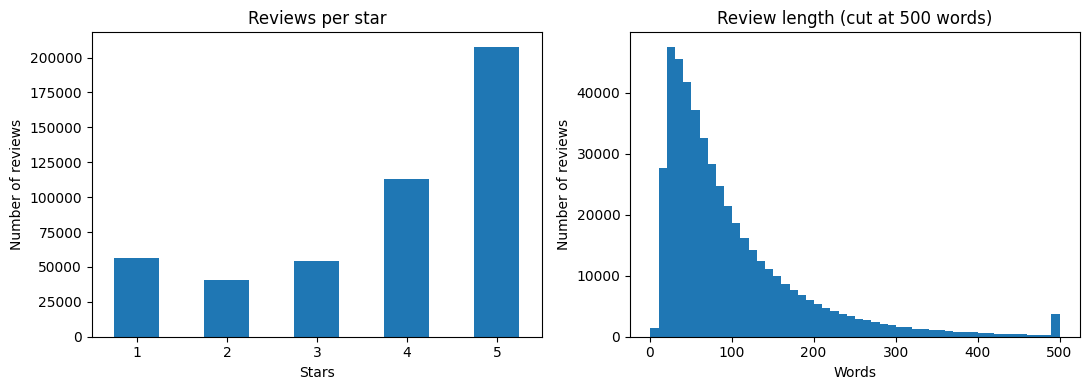

In [ ]:
star_counts = df["stars"].value_counts().sort_index()
print("Share of each star:")
print((star_counts / len(df)).round(3))

word_len = df["text"].str.split().str.len()
print("\nReview length (words):")
print(word_len.describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
star_counts.plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Reviews per star")
axes[0].set_xlabel("Stars")
axes[0].set_ylabel("Number of reviews")

axes[1].hist(word_len.clip(upper=500), bins=50)
axes[1].set_title("Review length (cut at 500 words)")
axes[1].set_xlabel("Words")
axes[1].set_ylabel("Number of reviews")
plt.tight_layout()
plt.show()

---
# Part 2: Look at the data and clean it (answer to the professor)

The professor asked us to print real reviews, see what they look like, clean the data more if needed, and report what changed.

### 2.1 Read the reviews ourselves

8 random reviews per star.

In [ ]:
for star in [1, 2, 3, 4, 5]:
    print("\n===== " + str(star) + " STAR =====")
    examples = df[df["stars"] == star].sample(8, random_state=SEED)
    for text in examples["text"]:
        print("-", text[:400].replace("\n", " "), "\n")


===== 1 STAR =====
- Just a terrible pizza.  Under cooked.  Very little cheese and sauce.  First time, last time.  Threw away the last couple slices - not worth freezing.  My friends here say it's not usually this bad - I sure hope not. 

- I have been a customer at 3 Margaritas since moving to the St. Louis area over 11 years ago. I actually drive past other Mexican restaurants to eat there. It's safe to say it's my favorite. Saturday I called in a to go order, was told it was be ready in 10 minutes. It took me 15 minutes to arrive and my order wasn't ready. They didn't say anything, other than it'll be just a minute, but I suspect  

- Hi, I never do this but I went into El Libre an early morning to get breakfast with my mother before she left town.  We're Cuban and since moving to New Orleans I had heard many amazing things about the restaurant and I wanted to show it off to her.  We came in a little after opening and were met with a very cold, stoic woman behind the counter.  It w

**Our notes on the 40 printed reviews:**

- **The text is clean.** Normal English sentences, some informal punctuation ("!!!!") and the odd typo. Almost no HTML, links or other languages (the counts in 2.2 confirm it).
- **Many reviews are mixed, whatever the star.** Several 1-star reviews praise the food and hate the service ("the food was good but the customer service was awful"). A 3-star review says "the food and service was great" and only complains about the price.
- **One incident decides the star.** "Awesome customer service. Awesome food ... I only gave four stars ... because the bathroom smells". The text reads as 5 stars, the label is 4.
- **Stars depend on the writer.** The same mild praise ("pretty good", "not bad") appears under 3, 4 and 5 stars.
- **Long stories, little opinion.** Many 1 to 3-star reviews tell what happened and give the verdict only at the end.
- **Sarcasm is rare** in this sample.

**Conclusion:** the data is not dirty. The difficulty is that neighbouring stars (2-3, 3-4, 4-5) are written in the same words, and one review often mixes praise and complaints.

### 2.2 Count the problems

In [ ]:
def non_english_share(text):
    # Share of characters that are not plain English letters or symbols (emoji, Chinese, ...)
    count = 0
    for character in text:
        if ord(character) > 127:
            count = count + 1
    return count / max(len(text), 1)


REPEAT = re.compile(r"([a-zA-Z])\1{2,}")      # 3 or more of the same letter: "sooo", "yummmm"

def has_repeated_letters(text):
    return REPEAT.search(text) is not None


non_english = df["text"].apply(non_english_share)
n_words = df["text"].str.split().str.len()
NEGATIVE_WORDS = r"worst|terrible|never again|disgusting"
POSITIVE_WORDS = r"amazing|best ever|highly recommend|delicious"

problems = {}
problems["reviews"] = len(df)
problems["under 3 words"] = (n_words < 3).sum()
problems["under 5 words"] = (n_words < 5).sum()
problems["over 500 words"] = (n_words > 500).sum()
problems["mostly non-English (30%+ non-ASCII)"] = (non_english > 0.30).sum()
problems["duplicates ignoring case"] = df["text"].str.lower().str.strip().duplicated().sum()
problems["contains URL"] = df["text"].str.contains(r"http|www\.", regex=True).sum()
problems["contains HTML entity or tag"] = df["text"].str.contains(r"&amp;|&#\d+;|&quot;|<br|<[a-z]+>", regex=True).sum()
problems["repeated letters (sooo)"] = df["text"].apply(has_repeated_letters).sum()
problems["5 stars with negative words"] = ((df["stars"] == 5) & df["text"].str.contains(NEGATIVE_WORDS, case=False)).sum()
problems["1 star with positive words"] = ((df["stars"] == 1) & df["text"].str.contains(POSITIVE_WORDS, case=False)).sum()

problems = pd.Series(problems).astype(int)
problems.to_csv(RESULTS + "/problem_counts.csv", header=["count"])
print(problems.to_string())

reviews                                472181
under 3 words                              31
under 5 words                              84
over 500 words                           3516
mostly non-English (30%+ non-ASCII)        41
duplicates ignoring case                    0
contains URL                              769
contains HTML entity or tag                 6
repeated letters (sooo)                 15867
5 stars with negative words               715
1 star with positive words               2063


In [ ]:
# A few examples of each problem
def show_examples(rows, n=3):
    for index, row in rows.head(n).iterrows():
        print(f"  [{row['stars']} stars] {row['text'][:250]!r}")


print("--- short reviews")
show_examples(df[n_words < 5])
print("--- mostly non-English")
show_examples(df[non_english > 0.30])
print("--- URL / HTML")
show_examples(df[df["text"].str.contains(r"http|www\.|&amp;|<br", regex=True)])
print("--- 5 stars, negative words")
show_examples(df[(df["stars"] == 5) & df["text"].str.contains(NEGATIVE_WORDS, case=False)])
print("--- 1 star, positive words")
show_examples(df[(df["stars"] == 1) & df["text"].str.contains(POSITIVE_WORDS, case=False)])

--- short reviews
  [5 stars] 'Great NY style pizza.'
  [4 stars] 'Awesome'
  [2 stars] 'Dreadful service. Good food.'
--- mostly non-English
  [4 stars] '建在码头上的海鲜餐厅面对大海的小屋 食材新鲜 在当地也有不错的口碑而且价格便宜. 尤其是海胆Uni第一次吃到这样的口味 柠檬搭配的恰到好处 微酸调出了多层次的口感与沾酱油的口味大不同.清蒸石头蟹新鲜价格合理'
  [4 stars] '午餐和晚餐菜单不一样，午餐简餐，晚上是正餐豪华一些，去的时候是中午后厨还是给做了几道主菜。\n\n【服务】热情 路过的人都会询问你的需求\n【环境】靠外部有吧台，小卡座，往里走有正经一些\n，装修还可以，不十分豪华但也得体\n【菜品】\n*烤生蚝：进口生蚝，具体哪里的还真不知道，无异味，上面有酥酥的菜，不错的前菜，一盘三个\n*带子：三个巨大的带子，轻微煎过，很嫩，还饱有汁水，但味道我觉得单一了一些，下面有超过的什锦蔬菜丁\n*海鲜墨鱼意面：奶味+虾味，清淡倒也回味，墨鱼面爽滑。配料十分丰富，大虾，龙虾钳肉，两'
  [2 stars] 'リノにはインド料理店が２店あります。この店は古くからあり、数年前に店舗の拡張するほど、美味しくにんきのある店"でした"。\n残念ながら、個々のカレーの特徴がなく、香辛料の味がしないうえに全て同じような味になってしまいました。\n香辛料の効いた美味しいカレーバッフェに行きたいのであれば、South Lake Tahoeまで足を伸ばすことをおすすめします。'
--- URL / HTML
  [2 stars] "This was our first time trying Cal Taco, as we just moved to town and it's a 3 minute walk from our apartment. You probably wouldn't notice the place unless you were looking for it, but it's less of a dive inside than you would think, i.e. chain-f

### 2.3 Clean the data

| Problem | Rule | Why |
|---|---|---|
| Duplicate text (ignoring case) | Drop | A duplicate could sit in both train and test |
| Under 3 words | Drop | Nothing to learn from |
| Mostly non-English | Drop | Our vocabulary and models are English only |
| URLs, HTML (`&amp;`, `<br>`), repeated letters ("sooo") | Clean the text, keep the review | Only noise |
| Mixed or sarcastic reviews | Keep | Real ambiguity, not dirty data |

In [ ]:
URL = re.compile(r"(https?://\S+|www\.\S+)", re.I)
TAG = re.compile(r"<[^>]+>")
PUNCT_REPEAT = re.compile(r"([!?.])\1{3,}")
SPACES = re.compile(r"\s+")

def clean_text(text):
    text = html.unescape(text)                # &amp; -> &   and   &#39; -> '
    text = TAG.sub(" ", text)                 # remove <br> and other HTML tags
    text = URL.sub(" ", text)                 # remove links
    text = REPEAT.sub(r"\1\1", text)          # "sooooo" -> "soo"
    text = PUNCT_REPEAT.sub(r"\1\1\1", text)  # "!!!!!!" -> "!!!"
    text = SPACES.sub(" ", text).strip()      # many spaces -> one space
    return text


report = {}
report["start"] = len(df)

# 1. Drop mostly non-English reviews
df_clean = df[non_english <= 0.30].copy()
report["dropped_non_english"] = report["start"] - len(df_clean)

# 2. Clean the text
before = df_clean["text"]
df_clean["text"] = df_clean["text"].apply(clean_text)
report["texts_changed_by_cleaning"] = int((before != df_clean["text"]).sum())

# 3. Drop reviews under 3 words
n_before = len(df_clean)
df_clean = df_clean[df_clean["text"].str.split().str.len() >= 3]
report["dropped_under_3_words"] = n_before - len(df_clean)

# 4. Drop duplicates (ignoring upper / lower case)
n_before = len(df_clean)
df_clean = df_clean[~df_clean["text"].str.lower().str.strip().duplicated()]
report["dropped_duplicates"] = n_before - len(df_clean)

report["end"] = len(df_clean)
save_json(report, "cleaning_report.json")
df_clean.to_parquet(DATA + "/yelp_restaurant_clean.parquet")
print(json.dumps(report, indent=2))

{
  "start": 472181,
  "dropped_non_english": 41,
  "texts_changed_by_cleaning": 269662,
  "dropped_under_3_words": 15,
  "dropped_duplicates": 4,
  "end": 472121
}


In [ ]:
# Before and after, for a few reviews the cleaning changed
compare = df.merge(df_clean[["review_id", "text"]], on="review_id", suffixes=("_raw", "_clean"))
compare = compare[compare["text_raw"] != compare["text_clean"]]
for index, row in compare.head(5).iterrows():
    print("RAW  :", row["text_raw"][:250].replace("\n", " "))
    print("CLEAN:", row["text_clean"][:250], "\n")

RAW  : Wow!  Yummy, different,  delicious.   Our favorite is the lamb curry and korma.  With 10 different kinds of naan!!!  Don't let the outside deter you (because we almost changed our minds)...go in and try something new!   You'll be glad you did!
CLEAN: Wow! Yummy, different, delicious. Our favorite is the lamb curry and korma. With 10 different kinds of naan!!! Don't let the outside deter you (because we almost changed our minds)...go in and try something new! You'll be glad you did! 

RAW  : The bun makes the Sonoran Dog. It's like a snuggie for the pup. A first, it seems ridiculous and almost like it's going to be too much, exactly like everyone's favorite blanket with sleeves. Too much softness, too much smush, too indulgent.  Wrong. I
CLEAN: The bun makes the Sonoran Dog. It's like a snuggie for the pup. A first, it seems ridiculous and almost like it's going to be too much, exactly like everyone's favorite blanket with sleeves. Too much softness, too much smush, too indulgent

### 2.4 Draft answer to the professor

Numbers from our runs (Appendix B has the raw vs cleaned comparison, Appendix E the learning curve and the dedicated models, Part 11 the human blind test):

> We printed and read 40 reviews (8 per star) and counted the usual problems in all 472,181 reviews: 41 mostly non-English, 31 under 3 words, 769 with links, 6 with HTML, 15,867 with repeated letters, no duplicates left. We cleaned all of them (dropped 60 reviews, normalized the text of 269,662) and re-trained. Logistic Regression went from 0.638 to 0.639 accuracy, and Naive Bayes did not change. So **data quality is not what limits the score.**
>
> What limits it is the 5-star scale itself: 88% of the errors are off by one star, and 95.6% of predictions are within one star. Neighbouring stars use the same words ("pretty good" appears under 3, 4 and 5 stars), and many reviews mix praise and complaints. More data does not help (the learning curve is flat after about 100,000 reviews). The same models reach about 83% on 3 classes, 96% on positive vs negative and 97% on 1 star vs 5 stars. DistilBERT reaches 66% on 5 stars, in line with published results on the Yelp 5-star benchmark (about 62 to 64% for bag-of-words models, 70 to 73% for large transformers).

---
# Part 3: Train, validation and test sets (split by restaurant)

If we split the reviews at random, reviews of the **same restaurant** end up in both train and test, which makes the scores look better than they are. So we split the **restaurants** 80 / 10 / 10 and take the reviews inside each part.

| Set | Size | Distribution | Why |
|---|---|---|---|
| **Train** | 5 x 20,000 | **balanced** (same number of each star) | otherwise the model just learns to say "5 stars" |
| **Validation** | 10,000 | **real** (imbalanced) | to choose settings |
| **Test** | 10,000 | **real** (imbalanced) | final score, used only once at the end |

**Every model from here on (including DistilBERT) uses these same three sets.**

In [ ]:
# 1. Shuffle the restaurants (same seed = same order every run)
business_ids = df_clean["business_id"].unique()
rng = np.random.RandomState(SEED)
rng.shuffle(business_ids)

# 2. 80% / 10% / 10% of the restaurants
n = len(business_ids)
train_ids = set(business_ids[:int(0.8 * n)])
val_ids = set(business_ids[int(0.8 * n):int(0.9 * n)])
test_ids = set(business_ids[int(0.9 * n):])

# 3. The reviews of each group of restaurants
train = df_clean[df_clean["business_id"].isin(train_ids)].groupby("stars", group_keys=False).sample(TRAIN_PER_STAR, random_state=SEED)
val = df_clean[df_clean["business_id"].isin(val_ids)].sample(EVAL_SIZE, random_state=SEED)
test = df_clean[df_clean["business_id"].isin(test_ids)].sample(EVAL_SIZE, random_state=SEED)

train.to_parquet(DATA + "/train.parquet")
val.to_parquet(DATA + "/val.parquet")
test.to_parquet(DATA + "/test.parquet")

# Check: no restaurant is in both train and test
assert len(set(train["business_id"]) & set(test["business_id"])) == 0

split_table = pd.DataFrame({"train": train["stars"].value_counts().sort_index(),
                            "validation": val["stars"].value_counts().sort_index(),
                            "test": test["stars"].value_counts().sort_index()})
split_table.loc["total"] = split_table.sum()
print(split_table)

        train  validation   test
stars                           
1       20000        1187   1166
2       20000         858    911
3       20000        1149   1191
4       20000        2389   2379
5       20000        4417   4353
total  100000       10000  10000


---
# Part 4: Text preprocessing

Same steps as in class: lowercase, tokenize, remove stopwords and punctuation. One change, because this is **sentiment**:

**Negation tagging.** *"not good"* is very different from *"good"*. Every word after a negation word (*not, no, never, n't, ...*) gets the prefix `NEG_`, until the next punctuation mark. So *"the food was not good, but ..."* becomes `food NEG_good ...`. The negation words themselves are kept (they are removed from the stopword list).

We also tried lemmatization (*dishes → dish*); it did not help (Appendix C), so it is off.

In [ ]:
NEG_WORDS = {"not", "no", "never", "n't", "cannot", "nothing", "nobody", "none", "neither", "nor"}
PUNCT = {".", ",", "!", "?", ";", ":"}
STOP = set(stopwords.words("english")) - NEG_WORDS
lemmatizer = WordNetLemmatizer()

def preprocess(text, use_neg=True, use_lemma=False):
    tokens = word_tokenize(text.lower())
    result = []
    in_negation = False
    for token in tokens:
        # Punctuation ends the negation
        if token in PUNCT:
            in_negation = False
            continue
        # A negation word: keep it, and tag the next words
        if token in NEG_WORDS:
            result.append(token)
            in_negation = use_neg
            continue
        # Remove stopwords, numbers and symbols
        if token in STOP or not token.isalpha():
            continue
        if use_lemma:
            token = lemmatizer.lemmatize(token)
        if in_negation:
            token = "NEG_" + token
        result.append(token)
    return " ".join(result)


print(preprocess("The food was not good, but the service wasn't terrible!"))

food not NEG_good service n't NEG_terrible


In [ ]:
# Preprocess the three sets (a few minutes)
start = time.time()
train["clean_text"] = [preprocess(text) for text in train["text"]]
val["clean_text"] = [preprocess(text) for text in val["text"]]
test["clean_text"] = [preprocess(text) for text in test["text"]]
print(f"done in {time.time() - start:.0f} seconds")
train[["text", "clean_text"]].head(3)

done in 203 seconds


,text,clean_text
147713,Where do I begin??? I didn't even get to taste...,begin n't NEG_even NEG_get NEG_taste NEG_food ...
331839,"service was awful, food was horrible. Do not e...",service awful food horrible not NEG_even NEG_w...
385357,"March 7, 2017 Friday - 12:15 PM for Lunch 2 ad...",march friday pm lunch adults went lunch cowork...


---
# Part 5: Naive Bayes, Logistic Regression and Linear SVM

- **TF-IDF** turns each review into a long vector (one number per word or word pair). `ngram_range=(1, 2)` = single words **and** pairs of words (*"NEG_good"*, *"highly recommend"*).
- A `Pipeline` = TF-IDF + classifier together, so the TF-IDF is fitted on the training part only.

### 5.1 Choose the settings with 5-fold cross-validation

For each model we try a few settings (`alpha` for Naive Bayes, `C` for LR and SVM) and keep the one with the best average macro-F1 over 5 folds. The folds are grouped by restaurant (a restaurant is in one fold only). This takes 20 to 40 minutes, so the best settings are saved in `cv_results.json` and reused in the next runs (delete that file to redo the search).

In [ ]:
def make_tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=50000)


CV_FILE = RESULTS + "/cv_results.json"

if os.path.exists(CV_FILE):
    with open(CV_FILE) as f:
        cv_results = json.load(f)
    print("Cross-validation was done in an earlier run: using its best settings.")
else:
    folds = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    searches = {
        "nb": (MultinomialNB(), {"clf__alpha": [0.1, 0.3, 1.0]}),
        "lr": (LogisticRegression(max_iter=1000), {"clf__C": [0.5, 1, 3]}),
        "svm": (LinearSVC(), {"clf__C": [0.1, 0.3, 1]}),
    }
    cv_results = {}
    for name in searches:
        classifier, settings = searches[name]
        start = time.time()
        pipe = Pipeline([("tfidf", make_tfidf()), ("clf", classifier)])
        search = GridSearchCV(pipe, settings, cv=folds, scoring="f1_macro", n_jobs=2)
        search.fit(train["clean_text"], train["stars"], groups=train["business_id"])
        best = search.best_index_
        cv_results[name] = {"best_params": search.best_params_,
                            "cv_macro_f1_mean": search.best_score_,
                            "cv_macro_f1_std": search.cv_results_["std_test_score"][best]}
        print(f"{name}: {search.best_params_} ({time.time() - start:.0f} s)")
    cv_results["text_version"] = "t_neg"
    save_json(cv_results, "cv_results.json")

for name in ["nb", "lr", "svm"]:
    print(f"{name}: best setting {cv_results[name]['best_params']}  "
          f"CV macro-F1 = {cv_results[name]['cv_macro_f1_mean']:.4f} ± {cv_results[name]['cv_macro_f1_std']:.4f}")

Cross-validation was done in an earlier run: using its best settings.
nb: best setting {'clf__alpha': 1.0}  CV macro-F1 = 0.5812 ± 0.0025
lr: best setting {'clf__C': 0.5}  CV macro-F1 = 0.6041 ± 0.0007
svm: best setting {'clf__C': 0.1}  CV macro-F1 = 0.5891 ± 0.0018


### 5.2 Train the three models with their best setting and test them once

In [ ]:
nb_alpha = cv_results["nb"]["best_params"]["clf__alpha"]
lr_C = cv_results["lr"]["best_params"]["clf__C"]
svm_C = cv_results["svm"]["best_params"]["clf__C"]

nb_model = Pipeline([("tfidf", make_tfidf()), ("clf", MultinomialNB(alpha=nb_alpha))])
lr_model = Pipeline([("tfidf", make_tfidf()), ("clf", LogisticRegression(C=lr_C, max_iter=1000))])
svm_model = Pipeline([("tfidf", make_tfidf()), ("clf", LinearSVC(C=svm_C))])

nb_model.fit(train["clean_text"], train["stars"])
lr_model.fit(train["clean_text"], train["stars"])
svm_model.fit(train["clean_text"], train["stars"])

preds = {}
preds["nb"] = nb_model.predict(test["clean_text"])
preds["lr"] = lr_model.predict(test["clean_text"])
preds["svm"] = svm_model.predict(test["clean_text"])

rows = []
rows.append(score(test["stars"], preds["nb"], "Naive Bayes", show_details=True))
rows.append(score(test["stars"], preds["lr"], "Logistic Regression", show_details=True))
rows.append(score(test["stars"], preds["svm"], "Linear SVM", show_details=True))
classical = pd.DataFrame(rows)
classical.insert(1, "split", "restaurant")
classical.to_csv(RESULTS + "/task_a_classical.csv", index=False)
classical.round(3)

===== Naive Bayes =====
              precision    recall  f1-score   support

           1      0.667     0.717     0.691      1166
           2      0.404     0.474     0.437       911
           3      0.438     0.465     0.451      1191
           4      0.493     0.532     0.512      2379
           5      0.815     0.721     0.765      4353

    accuracy                          0.622     10000
   macro avg      0.564     0.582     0.571     10000
weighted avg      0.639     0.622     0.629     10000

[[ 836  265   53    6    6]
 [ 230  432  211   33    5]
 [  95  253  554  245   44]
 [  39   76  342 1265  657]
 [  53   42  104 1017 3137]]
===== Logistic Regression =====
              precision    recall  f1-score   support

           1      0.699     0.739     0.718      1166
           2      0.423     0.496     0.457       911
           3      0.434     0.475     0.454      1191
           4      0.494     0.531     0.512      2379
           5      0.817     0.720     0.765

,model,split,accuracy,macro_f1,mae,within_1,acc_3class,macro_f1_3class,acc_binary
0,Naive Bayes,restaurant,0.622,0.571,0.454,0.944,0.839,0.726,0.92
1,Logistic Regression,restaurant,0.628,0.581,0.438,0.952,0.843,0.732,0.92
2,Linear SVM,restaurant,0.634,0.579,0.438,0.948,0.841,0.726,0.92


### 5.3 Class weights

The training set is balanced, but real reviews are not (44% are 5 stars), so the model predicts the rare stars too often. We multiply the LR probability of each star by a weight. The weights are chosen on the **validation** set (try a few values for one star at a time, keep the best, repeat 3 times), then used once on the test set.

In [ ]:
proba_val = lr_model.predict_proba(val["clean_text"])
stars = lr_model.classes_          # [1 2 3 4 5]
weights = np.ones(5)
options = [0.5, 0.75, 1, 1.25, 1.5, 2]

for round_number in range(3):
    for k in range(5):
        best_f1 = -1
        best_option = 1
        for option in options:
            trial = weights.copy()
            trial[k] = option
            pred = stars[(proba_val * trial).argmax(axis=1)]
            f1 = f1_score(val["stars"], pred, average="macro")
            if f1 >= best_f1:
                best_f1 = f1
                best_option = option
        weights[k] = best_option

print("weight per star:", dict(zip(stars.tolist(), weights.tolist())))

proba_test_lr = lr_model.predict_proba(test["clean_text"])
preds["lr_weighted"] = stars[(proba_test_lr * weights).argmax(axis=1)]

weighted = pd.DataFrame([score(test["stars"], preds["lr"], "LR"),
                         score(test["stars"], preds["lr_weighted"], "LR + class weights")])
save_json({"weights": dict(zip([str(s) for s in stars], weights))}, "class_weights.json")
weighted.round(4)

weight per star: {1: 1.0, 2: 1.0, 3: 1.0, 4: 1.25, 5: 1.5}


,model,accuracy,macro_f1,mae,within_1,acc_3class,macro_f1_3class,acc_binary
0,LR,0.6277,0.5812,0.4383,0.9524,0.8426,0.7321,0.9199
1,LR + class weights,0.6440,0.5881,0.4167,0.9558,0.8542,0.7368,0.9360


In [ ]:
# Save the test predictions of every model (the comparison in Part 7 reads these files)
save_preds("nb", preds["nb"])
save_preds("lr", preds["lr"], proba_test_lr)
save_preds("svm", preds["svm"])
save_preds("lr_weighted", preds["lr_weighted"])
print(sorted(f for f in os.listdir(RESULTS) if f.startswith("preds_")))

['preds_distilbert.csv', 'preds_lr.csv', 'preds_lr_weighted.csv', 'preds_nb.csv', 'preds_svm.csv']


---
# Part 6: DistilBERT for star rating

**DistilBERT** is a smaller version of BERT, a transformer that was pre-trained on a lot of English text. We **fine-tune** it: we add an output layer with 5 outputs (one per star) and train the whole network a little more on our reviews. Unlike TF-IDF, it reads the words **in order**, so it can understand *"not bad at all"*.

- It uses the original text (it has its own tokenizer), not our `clean_text`.
- 50,000 training reviews (10,000 per star), 2 epochs, reviews cut at 128 tokens.
- It needs the T4 GPU (about 30 minutes). The trained model is saved in `models/distilbert_task_a`, and the next runs load it instead of training again.

In [ ]:
DB_A_PATH = MODELS + "/distilbert_task_a"
DB_A_PREDS = RESULTS + "/preds_distilbert.csv"

if os.path.exists(DB_A_PATH + "/config.json") and os.path.exists(DB_A_PREDS):
    TRAIN_DB_A = False
    print("DistilBERT was trained in an earlier run: its saved test predictions are used.")
elif HAS_GPU:
    TRAIN_DB_A = True
    print("Training DistilBERT now.")
else:
    TRAIN_DB_A = False
    print("No GPU and no saved model: DistilBERT is skipped. In Colab: Runtime > Change runtime type > T4 GPU.")


def compute_metrics(prediction):
    # Accuracy and macro-F1 on the validation set after each epoch
    pred = prediction.predictions.argmax(axis=-1)
    return {"accuracy": accuracy_score(prediction.label_ids, pred),
            "macro_f1": f1_score(prediction.label_ids, pred, average="macro")}

DistilBERT was trained in an earlier run: its saved test predictions are used.


In [ ]:
if TRAIN_DB_A:
    tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

    # 10,000 reviews per star (400 in QUICK mode)
    per_star = 10000
    if QUICK:
        per_star = 400
    db_train = train.groupby("stars", group_keys=False).sample(per_star, random_state=SEED)

    def tokenize(batch):
        return tokenizer(batch["text"], truncation=True, max_length=128)

    def make_dataset(data):
        # Labels 0 to 4 (stars minus 1)
        table = pd.DataFrame({"text": data["text"].values, "label": data["stars"].values - 1})
        dataset = Dataset.from_pandas(table, preserve_index=False)
        return dataset.map(tokenize, batched=True)

    train_ds = make_dataset(db_train)
    val_ds = make_dataset(val)
    test_ds = make_dataset(test)

    db_model = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=5)
    args = TrainingArguments(
        output_dir=MODELS + "/distilbert_ckpt",
        learning_rate=2e-5,
        per_device_train_batch_size=32,
        per_device_eval_batch_size=64,
        num_train_epochs=1 if QUICK else 2,
        weight_decay=0.01,
        fp16=torch.cuda.is_available(),
        seed=SEED,
        report_to="none",
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        save_total_limit=1,
        logging_steps=200,
    )
    trainer = Trainer(model=db_model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                      data_collator=DataCollatorWithPadding(tokenizer), compute_metrics=compute_metrics)
    trainer.train()

    log = pd.DataFrame(trainer.state.log_history)
    log.to_csv(RESULTS + "/distilbert_task_a_log.csv", index=False)
    print(log)

In [ ]:
if TRAIN_DB_A:
    # Predict the test set once, save the predictions and the model
    output = trainer.predict(test_ds)
    proba_db = torch.softmax(torch.tensor(output.predictions), dim=1).numpy()
    preds["distilbert"] = proba_db.argmax(axis=1) + 1
    save_preds("distilbert", preds["distilbert"], proba_db)
    trainer.save_model(DB_A_PATH)
    tokenizer.save_pretrained(DB_A_PATH)
    print("model saved to", DB_A_PATH)

if os.path.exists(DB_A_PREDS):
    saved = pd.read_csv(DB_A_PREDS).set_index("review_id").loc[test["review_id"]]
    preds["distilbert"] = saved["y_pred"].values
    score(test["stars"], preds["distilbert"], "DistilBERT", show_details=True)

===== DistilBERT =====
              precision    recall  f1-score   support

           1      0.756     0.725     0.740      1166
           2      0.463     0.563     0.508       911
           3      0.479     0.563     0.517      1191
           4      0.527     0.551     0.539      2379
           5      0.838     0.749     0.791      4353

    accuracy                          0.660     10000
   macro avg      0.613     0.630     0.619     10000
weighted avg      0.678     0.660     0.667     10000

[[ 845  278   33    5    5]
 [ 198  513  178   19    3]
 [  39  255  670  200   27]
 [  17   39  419 1311  593]
 [  18   24  100  951 3260]]


---
# Part 7: Compare all star-rating models

Built from the saved `preds_*.csv` files, so a model trained in an earlier run is also included.

In [ ]:
MODEL_NAMES = {"nb": "Naive Bayes", "lr": "Logistic Regression", "lr_weighted": "LR + class weights",
               "svm": "Linear SVM", "distilbert": "DistilBERT"}

saved_preds = {}
rows = []
for key in MODEL_NAMES:
    file = RESULTS + "/preds_" + key + ".csv"
    if os.path.exists(file):
        saved_preds[key] = pd.read_csv(file)
        rows.append(score(saved_preds[key]["y_true"], saved_preds[key]["y_pred"], MODEL_NAMES[key]))

comparison = pd.DataFrame(rows).set_index("model")
comparison.to_csv(RESULTS + "/task_a_comparison.csv")

# The best model (highest macro-F1) is used in the error analysis (Part 11)
BEST_A = None
best_f1 = -1
for key in saved_preds:
    f1 = comparison.loc[MODEL_NAMES[key], "macro_f1"]
    if f1 > best_f1:
        best_f1 = f1
        BEST_A = key
print("Best star-rating model (macro-F1):", MODEL_NAMES[BEST_A])
comparison.round(3)

Best star-rating model (macro-F1): DistilBERT


,accuracy,macro_f1,mae,within_1,acc_3class,macro_f1_3class,acc_binary
model,,,,,,,
Naive Bayes,0.622,0.571,0.454,0.944,0.839,0.726,0.920
Logistic Regression,0.628,0.581,0.438,0.952,0.843,0.732,0.920
LR + class weights,0.644,0.588,0.417,0.956,0.854,0.737,0.936
Linear SVM,0.634,0.579,0.438,0.948,0.841,0.726,0.920
DistilBERT,0.660,0.619,0.382,0.967,0.862,0.768,0.926


---
# Part 8: ABSA data (SemEval restaurant sentences)

For ABSA we need sentences where a person marked the aspects and their sentiment. We use **SemEval-2014** (restaurant reviews, 3,044 sentences). Its aspect names are mapped to ours: `food` → Food Quality, `service` → Service, `ambience` → Atmosphere (`price` and `anecdotes/miscellaneous` are ignored).

- The official test file has the aspects but **not** the sentiment, so we split the 3,044 sentences 80 / 20 (seed 45): 80% to train (of which 20% to choose settings), 20% to test. The official 800-sentence test file is an extra test for aspect detection only.
- **More training data:** the **SemEval-2016** restaurant sentences (same 3 aspects, other reviews) are added to the **training** sentences only. Sentences that also appear in our validation or test sentences are removed first.

In [ ]:
import xml.etree.ElementTree as ET

SEM_DIR = DATA + "/semeval"
SEM14_TRAIN = SEM_DIR + "/Restaurants_Train.xml"
SEM14_TEST = SEM_DIR + "/Restaurants_Test_Data_phaseB.xml"
SEM16_TRAIN = SEM_DIR + "/ABSA16_Restaurants_Train_SB1_v2.xml"

# Download once from GitHub (the repository named in our proposal)
if not (os.path.exists(SEM14_TRAIN) and os.path.exists(SEM16_TRAIN)):
    os.system("rm -rf /tmp/absa && git clone -q --depth 1 https://github.com/davidsbatista/Aspect-Based-Sentiment-Analysis.git /tmp/absa")
    os.makedirs(SEM_DIR, exist_ok=True)
    os.system(f"cp /tmp/absa/datasets/ABSA-SemEval2014/Restaurants* '{SEM_DIR}/'")
    os.system(f"cp /tmp/absa/datasets/ABSA-SemEval2016/Training_Data/ABSA16_Restaurants_Train_SB1_v2.xml '{SEM_DIR}/'")
print(sorted(os.listdir(SEM_DIR)))

['ABSA16_Restaurants_Train_SB1_v2.xml', 'Restaurants_Test_Data_PhaseA.xml', 'Restaurants_Test_Data_phaseB.xml', 'Restaurants_Train.xml', 'Restaurants_Train_v2.xml']


In [ ]:
ASPECTS = ["Food Quality", "Service", "Atmosphere"]
MAP_2014 = {"food": "Food Quality", "service": "Service", "ambience": "Atmosphere"}
MAP_2016 = {"FOOD#QUALITY": "Food Quality", "FOOD#STYLE_OPTIONS": "Food Quality",
            "SERVICE#GENERAL": "Service", "AMBIENCE#GENERAL": "Atmosphere"}

def read_semeval_2014(path):
    # One row per sentence: id, text, and the sentiment of each aspect (None = not mentioned)
    rows = []
    for sentence in ET.parse(path).getroot().iter("sentence"):
        row = {"id": sentence.get("id"), "text": sentence.find("text").text}
        for aspect in ASPECTS:
            row[aspect] = None
        categories = sentence.find("aspectCategories")
        if categories is not None:
            for category in categories.findall("aspectCategory"):
                name = category.get("category")
                if name in MAP_2014:
                    polarity = category.get("polarity")
                    if not polarity:
                        polarity = "unknown"     # the official test file has no sentiment
                    row[MAP_2014[name]] = polarity
        rows.append(row)
    return pd.DataFrame(rows)


def read_semeval_2016(path):
    # Same table from the 2016 file (other XML format)
    rows = []
    for sentence in ET.parse(path).getroot().iter("sentence"):
        row = {"id": "16_" + sentence.get("id"), "text": sentence.find("text").text}
        for aspect in ASPECTS:
            row[aspect] = None
        opinions = sentence.find("Opinions")
        if opinions is not None:
            for opinion in opinions.findall("Opinion"):
                aspect = MAP_2016.get(opinion.get("category"))
                if aspect is None:
                    continue
                polarity = opinion.get("polarity")
                # Two opinions on the same aspect with a different sentiment = "conflict"
                if row[aspect] is None or row[aspect] == polarity:
                    row[aspect] = polarity
                else:
                    row[aspect] = "conflict"
        rows.append(row)
    return pd.DataFrame(rows)


sem = read_semeval_2014(SEM14_TRAIN)
sem_official = read_semeval_2014(SEM14_TEST)
print(f"SemEval-2014 train file: {len(sem)} sentences | official test file: {len(sem_official)} sentences")
print(sem[ASPECTS].notna().sum().to_string())

SemEval-2014 train file: 3044 sentences | official test file: 800 sentences
Food Quality    1233
Service          597
Atmosphere       432


In [ ]:
# 80% train / 20% test, then 20% of the train part for validation
sem_train, sem_test = train_test_split(sem, test_size=0.2, random_state=SEED)
det_train, det_val = train_test_split(sem_train, test_size=0.2, random_state=SEED)

# SemEval-2016 sentences: training only, without any sentence that is in validation or test
held_out = set(pd.concat([det_val, sem_test])["text"].str.lower().str.strip())
sem16 = read_semeval_2016(SEM16_TRAIN)
sem16 = sem16[~sem16["text"].str.lower().str.strip().isin(held_out)]

det_train_all = pd.concat([det_train, sem16], ignore_index=True)     # to train the aspect detectors
sent_train_all = pd.concat([sem_train, sem16], ignore_index=True)    # to train the sentiment models

print("Extra 2016 training sentences:", len(sem16))
print("Detection: train", len(det_train_all), "| validation", len(det_val), "| test", len(sem_test))


def aspect_matrix(data):
    # 1 if the sentence talks about the aspect, else 0 (one column per aspect)
    return data[ASPECTS].notna().astype(int).values

Extra 2016 training sentences: 1566
Detection: train 3514 | validation 487 | test 609


---
# Part 9: ABSA step 1 - which aspects does a sentence talk about?

A sentence can talk about several aspects, or none. We compare three detectors:
1. **Rules**: a list of words and short phrases per aspect (*waiter, rude, decor, delicious, ...*).
2. **TF-IDF + Logistic Regression**: one yes / no classifier per aspect.
3. **DistilBERT**: fine-tuned with 3 yes / no outputs.

### 9.1 Detector 1: rules

We start with our own list of phrases, then add the 40 words and phrases (1 to 3 words) most linked to each aspect in the **training** sentences (chi-square test).

In [ ]:
SEED_LEXICON = {
    "Food Quality": {"food", "dish", "dishes", "pizza", "delicious", "tasty", "flavor", "menu", "fresh", "sushi", "meal",
                     "dessert", "taste", "bland", "pasta", "chicken", "appetizer", "portions"},
    "Service": {"waiter", "waitress", "staff", "service", "slow", "rude", "waited forever", "server", "friendly",
                "attentive", "manager", "hostess", "wait", "served"},
    "Atmosphere": {"atmosphere", "ambiance", "ambience", "decor", "music", "cozy", "noisy", "loud", "romantic",
                   "setting", "interior", "space", "room", "crowded"},
}

# Count every 1-3 word phrase in the training sentences
counter = CountVectorizer(ngram_range=(1, 3), min_df=3, binary=True, lowercase=True)
X_counts = counter.fit_transform(det_train_all["text"])
phrases = np.array(counter.get_feature_names_out())
y_train_aspects = aspect_matrix(det_train_all)

LEXICON = {}
for k, aspect in enumerate(ASPECTS):
    y = y_train_aspects[:, k]
    chi_scores, p_values = chi2(X_counts, y)
    # Keep only phrases that are more frequent in sentences WITH this aspect
    rate_with = np.asarray(X_counts[y == 1].mean(axis=0)).ravel()
    rate_without = np.asarray(X_counts[y == 0].mean(axis=0)).ravel()
    chi_scores[rate_with <= 2 * rate_without] = 0
    top_phrases = phrases[np.argsort(-chi_scores)][:40]
    new_phrases = [p for p in top_phrases if p not in STOP]
    LEXICON[aspect] = SEED_LEXICON[aspect] | set(new_phrases)
    print(f"{aspect}: added {sorted(set(new_phrases) - SEED_LEXICON[aspect])[:12]} ...")


def ngrams(text, n=3):
    # All phrases of 1 to 3 words in a sentence
    words = re.findall(r"[a-z']+", text.lower())
    result = set()
    for size in range(1, n + 1):
        for i in range(len(words) - size + 1):
            result.add(" ".join(words[i:i + size]))
    return result


def rule_detect(texts):
    result = []
    for text in texts:
        found = ngrams(text)
        row = []
        for aspect in ASPECTS:
            if found & LEXICON[aspect]:
                row.append(1)
            else:
                row.append(0)
        result.append(row)
    return np.array(result)

Food Quality: added ['amazing', 'and the', 'and the food', 'best', 'but the', 'cooked', 'delicious and', 'excellent', 'fish', 'food is', 'food was', 'fresh and'] ...
Service: added ['and service', 'and the', 'and the service', 'asked', 'asked for', 'attentive and', 'friendly and', 'great service', 'helpful', 'service and', 'service is', 'service was'] ...
Atmosphere: added ['ambience is', 'and atmosphere', 'and nice', 'atmosphere is', 'beautiful', 'conversation', 'cramped', 'cramped and', 'cute', 'decor is', 'feel', 'jazz'] ...


### 9.2 Detector 2: TF-IDF + Logistic Regression

One class-balanced yes / no Logistic Regression per aspect. A sentence gets the aspect if the probability is above a **threshold**, and the threshold of each aspect is chosen on the validation sentences (the one with the best F1).

In [ ]:
def best_thresholds(proba, gold):
    # For each aspect, the threshold (0.10, 0.15, ..., 0.90) with the best F1
    thresholds = []
    for k in range(len(ASPECTS)):
        best_t = None
        best_f1 = -1
        for t in np.arange(0.1, 0.91, 0.05):
            f1 = f1_score(gold[:, k], proba[:, k] >= t)
            if f1 > best_f1:
                best_f1 = f1
                best_t = t
        thresholds.append(float(best_t))
    return thresholds


detector = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
                     ("ovr", OneVsRestClassifier(LogisticRegression(class_weight="balanced", max_iter=2000)))])
detector.fit(det_train_all["text"], aspect_matrix(det_train_all))

THR = best_thresholds(detector.predict_proba(det_val["text"]), aspect_matrix(det_val))
print("thresholds:", dict(zip(ASPECTS, np.round(THR, 2))))


def ml_detect(texts):
    proba = detector.predict_proba(list(texts))
    return (proba >= np.array(THR)).astype(int)

thresholds: {'Food Quality': np.float64(0.45), 'Service': np.float64(0.5), 'Atmosphere': np.float64(0.55)}


### 9.3 Detector 3: DistilBERT

DistilBERT with 3 outputs, one yes / no per aspect (multi-label), 5 epochs (about 3 minutes on a T4). Thresholds chosen on the validation sentences, as above. Saved in `models/distilbert_aspect_detector` and loaded in the next runs.

In [ ]:
DET_PATH = MODELS + "/distilbert_aspect_detector"
db_det = None

if os.path.exists(DET_PATH + "/config.json"):
    print("Loading the DistilBERT aspect detector trained in an earlier run.")
    tok_det = AutoTokenizer.from_pretrained(DET_PATH)
    db_det = AutoModelForSequenceClassification.from_pretrained(DET_PATH).to(DEVICE).eval()

elif HAS_GPU:
    tok_det = AutoTokenizer.from_pretrained("distilbert-base-uncased")

    def tokenize_det(batch):
        return tok_det(batch["text"], truncation=True, max_length=96)

    def make_det_dataset(data):
        labels = aspect_matrix(data).astype("float32").tolist()
        dataset = Dataset.from_dict({"text": list(data["text"]), "labels": labels})
        return dataset.map(tokenize_det, batched=True)

    def multilabel_metrics(prediction):
        proba = 1 / (1 + np.exp(-prediction.predictions))     # sigmoid
        return {"micro_f1": f1_score(prediction.label_ids, proba >= 0.5, average="micro")}

    model = AutoModelForSequenceClassification.from_pretrained(
        "distilbert-base-uncased", num_labels=3, problem_type="multi_label_classification")
    args = TrainingArguments(
        output_dir=MODELS + "/distilbert_det_ckpt",
        learning_rate=3e-5,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=64,
        num_train_epochs=1 if QUICK else 5,
        weight_decay=0.01,
        seed=SEED,
        fp16=torch.cuda.is_available(),
        report_to="none",
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="micro_f1",
        save_total_limit=1,
    )
    trainer_det = Trainer(model=model, args=args, train_dataset=make_det_dataset(det_train_all),
                          eval_dataset=make_det_dataset(det_val), data_collator=DataCollatorWithPadding(tok_det),
                          compute_metrics=multilabel_metrics)
    trainer_det.train()
    trainer_det.save_model(DET_PATH)
    tok_det.save_pretrained(DET_PATH)
    db_det = trainer_det.model.eval()

else:
    print("No GPU and no saved model: the DistilBERT detector is skipped.")

Loading the DistilBERT aspect detector trained in an earlier run.


Loading weights:   0%|          | 0/104 [00:01<?, ?it/s]

In [ ]:
def distilbert_detect_proba(texts, batch_size=64):
    # Probability of each aspect, 64 sentences at a time
    texts = list(texts)
    all_proba = []
    for i in range(0, len(texts), batch_size):
        batch = tok_det(texts[i:i + batch_size], truncation=True, max_length=96, padding=True,
                        return_tensors="pt").to(db_det.device)
        with torch.no_grad():
            proba = torch.sigmoid(db_det(**batch).logits)
        all_proba.append(proba.cpu().numpy())
    return np.vstack(all_proba)


def distilbert_detect(texts):
    return (distilbert_detect_proba(texts) >= np.array(THR_DB)).astype(int)


DETECTORS = {"rules": rule_detect, "ml": ml_detect}
if db_det is not None:
    THR_DB = best_thresholds(distilbert_detect_proba(det_val["text"]), aspect_matrix(det_val))
    print("DistilBERT thresholds:", dict(zip(ASPECTS, np.round(THR_DB, 2))))
    DETECTORS["distilbert"] = distilbert_detect

# Choose the detector for the full pipeline on the VALIDATION sentences
BEST_DETECTOR = None
best_f1 = -1
for name in DETECTORS:
    f1 = f1_score(aspect_matrix(det_val), DETECTORS[name](det_val["text"]), average="micro")
    print(f"validation micro-F1 {name}: {f1:.3f}")
    if f1 > best_f1:
        best_f1 = f1
        BEST_DETECTOR = name
print("Detector used in the pipeline:", BEST_DETECTOR)

DistilBERT thresholds: {'Food Quality': np.float64(0.35), 'Service': np.float64(0.4), 'Atmosphere': np.float64(0.55)}
validation micro-F1 rules: 0.703
validation micro-F1 ml: 0.798
validation micro-F1 distilbert: 0.884
Detector used in the pipeline: distilbert


### 9.4 Compare the detectors on the test sentences

Precision, recall and F1 per aspect, on our 20% test sentences and on the official test file. Plus the special case from our proposal: sentences with an aspect but **none** of the rule phrases (indirect mentions, like *"we waited forever"* for Service). The rules get 0 recall there by construction; the question is how much the other detectors find.

In [ ]:
def detection_table(data, test_name):
    rows = []
    gold = aspect_matrix(data)
    for name in DETECTORS:
        pred = DETECTORS[name](data["text"])

        # Per aspect
        precision, recall, f1, support = precision_recall_fscore_support(gold, pred, zero_division=0)
        for k, aspect in enumerate(ASPECTS):
            rows.append({"test_set": test_name, "detector": name, "aspect": aspect, "precision": precision[k],
                         "recall": recall[k], "f1": f1[k], "support": support[k]})

        # All aspects together (micro average)
        precision, recall, f1, support = precision_recall_fscore_support(gold, pred, average="micro", zero_division=0)
        rows.append({"test_set": test_name, "detector": name, "aspect": "all (micro)", "precision": precision,
                     "recall": recall, "f1": f1, "support": gold.sum()})

        # Indirect mentions: the aspect is there, but no rule phrase is in the sentence
        for k, aspect in enumerate(ASPECTS):
            no_phrase = np.array([len(ngrams(text) & LEXICON[aspect]) == 0 for text in data["text"]])
            indirect = (gold[:, k] == 1) & no_phrase
            if indirect.sum() > 0:
                rows.append({"test_set": test_name, "detector": name, "aspect": aspect + " (indirect only)",
                             "precision": np.nan, "recall": pred[indirect, k].mean(), "f1": np.nan,
                             "support": int(indirect.sum())})
    return rows


det_results = pd.DataFrame(detection_table(sem_test, "20% hold-out") + detection_table(sem_official, "official test (800)"))
det_results.to_csv(RESULTS + "/task_b_detection.csv", index=False)
det_results.pivot_table(index=["test_set", "aspect"], columns="detector", values=["precision", "recall", "f1"], sort=False).round(3)

precision                    \
detector                                             rules     ml distilbert   
test_set            aspect                                                     
20% hold-out        Food Quality                     0.746  0.804      0.862   
                    Service                          0.689  0.787      0.879   
                    Atmosphere                       0.437  0.733      0.850   
                    all (micro)                      0.670  0.790      0.865   
                    Food Quality (indirect only)       NaN    NaN        NaN   
                    Service (indirect only)            NaN    NaN        NaN   
                    Atmosphere (indirect only)         NaN    NaN        NaN   
official test (800) Food Quality                     0.841  0.887      0.939   
                    Service                          0.681  0.829      0.919   
                    Atmosphere                       0.538  0.757      0.925   
                    all (micro)                      0.735  0.851      0.932   
                    Food Quality (indirect only)       NaN    NaN        NaN   
                    Service (indirect only)            NaN    NaN        NaN   
                    Atmosphere (indirect only)         NaN    NaN        NaN   

                                                 recall                    \
detector                                          rules     ml distilbert   
test_set            aspect                                                  
20% hold-out        Food Quality                  0.812  0.867      0.953   
                    Service                       0.745  0.810      0.847   
                    Atmosphere                    0.584  0.571      0.662   
                    all (micro)                   0.755  0.802      0.874   
                    Food Quality (indirect only)  0.000  0.604      0.833   
                    Service (indirect only)       0.000  0.486      0.571   
                    Atmosphere (indirect only)    0.000  0.188      0.406   
official test (800) Food Quality                  0.794  0.897      0.955   
                    Service                       0.820  0.843      0.924   
                    Atmosphere                    0.712  0.737      0.831   
                    all (micro)                   0.787  0.857      0.927   
                    Food Quality (indirect only)  0.000  0.698      0.895   
                    Service (indirect only)       0.000  0.323      0.613   
                    Atmosphere (indirect only)    0.000  0.382      0.618   

                                                     f1                    
detector                                          rules     ml distilbert  
test_set            aspect                                                 
20% hold-out        Food Quality                  0.778  0.835      0.905  
                    Service                       0.716  0.799      0.862  
                    Atmosphere                    0.500  0.642      0.745  
                    all (micro)                   0.710  0.796      0.870  
                    Food Quality (indirect only)    NaN    NaN        NaN  
                    Service (indirect only)         NaN    NaN        NaN  
                    Atmosphere (indirect only)      NaN    NaN        NaN  
official test (800) Food Quality                  0.817  0.892      0.947  
                    Service                       0.744  0.836      0.922  
                    Atmosphere                    0.613  0.747      0.875  
                    all (micro)                   0.760  0.854      0.929  
                    Food Quality (indirect only)    NaN    NaN        NaN  
                    Service (indirect only)         NaN    NaN        NaN  
                    Atmosphere (indirect only)      NaN    NaN        NaN

---
# Part 10: ABSA step 2 - positive or negative about that aspect?

Once we know a sentence talks about an aspect, is it positive or negative about it? Neutral and conflict are left out (too rare, as in our proposal).

### 10.1 Sentence-aspect pairs

One row per (sentence, aspect) with a positive or negative label. A sentence about Food and Service gives two rows.

In [ ]:
def make_pairs(data):
    rows = []
    for index, row in data.iterrows():
        for aspect in ASPECTS:
            if row[aspect] in ("positive", "negative"):
                rows.append({"id": row["id"], "text": row["text"], "aspect": aspect, "label": row[aspect]})
    return pd.DataFrame(rows)


pairs_train = make_pairs(sent_train_all)    # 2014 + 2016
pairs_test = make_pairs(sem_test)

counts = pd.concat([pairs_train.assign(split="train"), pairs_test.assign(split="test")])
counts = counts.groupby(["aspect", "label", "split"]).size().unstack()
counts.to_csv(RESULTS + "/task_b_pair_counts.csv")
counts

split                  test  train
aspect       label                
Atmosphere   negative    16    112
             positive    48    344
Food Quality negative    44    303
             positive   179   1070
Service      negative    44    348
             positive    81    376

### 10.2 Model 1: TF-IDF + Logistic Regression, looking only at the part about the aspect

- **One shared model** for all three aspects (about 2,700 training pairs). `C` is chosen with 5-fold cross-validation.
- **Only the part of the sentence about the aspect.** The sentence is split at *but, and, although, however,* commas, ...; the TF-IDF detector from 9.2 finds the part(s) about the aspect, and only those are scored. So in *"The soup was cold and the waiter was rude"*, Service is judged on *"the waiter was rude"* only.

In [ ]:
search = GridSearchCV(Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=1, sublinear_tf=True)),
                                ("clf", LogisticRegression(class_weight="balanced", max_iter=3000))]),
                      {"clf__C": [0.3, 1, 3, 10]}, scoring="f1_macro",
                      cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
search.fit(pairs_train["text"], pairs_train["label"])
lr_sent = search.best_estimator_

cv_b = {"C": search.best_params_["clf__C"], "cv_macro_f1_mean": search.best_score_,
        "cv_macro_f1_std": search.cv_results_["std_test_score"][search.best_index_], "n_pairs": len(pairs_train)}
save_json(cv_b, "task_b_cv_lr.json")
print(f"best C = {cv_b['C']}  CV macro-F1 = {cv_b['cv_macro_f1_mean']:.3f} ± {cv_b['cv_macro_f1_std']:.3f}")

best C = 10  CV macro-F1 = 0.819 ± 0.014


In [ ]:
CLAUSE_SPLIT = re.compile(r"\s*(?:\bbut\b|\balthough\b|\bthough\b|\bhowever\b|\bwhile\b|\bexcept\b|;|\band\b|,)\s*", re.I)

def clauses(text):
    # Split a sentence into parts; keep parts with 2 words or more
    parts = []
    for part in CLAUSE_SPLIT.split(text):
        if part and len(part.split()) >= 2:
            parts.append(part)
    if len(parts) == 0:
        parts = [text]
    return parts


def aspect_part(text, aspect):
    # The part(s) of the sentence about the aspect, found with the TF-IDF detector
    parts = clauses(text)
    if len(parts) == 1:
        return text
    k = ASPECTS.index(aspect)
    proba = detector.predict_proba(parts)[:, k]
    keep = []
    for part, p in zip(parts, proba):
        if p >= THR[k]:
            keep.append(part)
    if len(keep) == 0:
        keep = [parts[int(np.argmax(proba))]]    # none above the threshold: take the most likely part
    return " ".join(keep)


def lr_sentiment(texts, aspects):
    parts = []
    for text, aspect in zip(texts, aspects):
        parts.append(aspect_part(text, aspect))
    return lr_sent.predict(parts)


for text, aspect in [("The soup was cold and the waiter was rude.", "Service"),
                     ("The food was great but the service was painfully slow.", "Food Quality")]:
    print(f"{aspect}: {text!r} -> part {aspect_part(text, aspect)!r} -> {lr_sentiment([text], [aspect])[0]}")

Service: 'The soup was cold and the waiter was rude.' -> part 'the waiter was rude.' -> negative
Food Quality: 'The food was great but the service was painfully slow.' -> part 'The food was great' -> positive


### 10.3 Model 2: DistilBERT with two inputs (sentence, aspect)

The tokenizer gets **two texts**: the sentence and the aspect name (*"The soup was cold and the waiter was rude"*, *"Service"*). The model reads both, so it can learn by itself which part of the sentence is about the aspect. 2 outputs: positive or negative. 4 epochs, a few minutes on a T4. Saved in `models/distilbert_task_b`.

In [ ]:
DB_B_PATH = MODELS + "/distilbert_task_b"
db_sent = None

if os.path.exists(DB_B_PATH + "/config.json"):
    print("Loading the DistilBERT sentiment model trained in an earlier run.")
    tok_sent = AutoTokenizer.from_pretrained(DB_B_PATH)
    db_sent = AutoModelForSequenceClassification.from_pretrained(DB_B_PATH).to(DEVICE).eval()

elif HAS_GPU:
    tok_sent = AutoTokenizer.from_pretrained("distilbert-base-uncased")
    # 15% of the training pairs to check each epoch
    pairs_fit, pairs_val = train_test_split(pairs_train, test_size=0.15, random_state=SEED,
                                            stratify=pairs_train["aspect"] + pairs_train["label"])

    def tokenize_pair(batch):
        return tok_sent(batch["text"], batch["aspect"], truncation=True, max_length=128)

    def make_pair_dataset(data):
        table = pd.DataFrame({"text": data["text"].values, "aspect": data["aspect"].values,
                              "label": (data["label"] == "positive").astype(int).values})   # 1 = positive
        dataset = Dataset.from_pandas(table, preserve_index=False)
        return dataset.map(tokenize_pair, batched=True)

    model = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2)
    args = TrainingArguments(
        output_dir=MODELS + "/distilbert_b_ckpt_45",
        learning_rate=3e-5,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=64,
        num_train_epochs=1 if QUICK else 4,
        weight_decay=0.01,
        seed=SEED,
        fp16=torch.cuda.is_available(),
        report_to="none",
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        save_total_limit=1,
    )
    trainer_sent = Trainer(model=model, args=args, train_dataset=make_pair_dataset(pairs_fit),
                           eval_dataset=make_pair_dataset(pairs_val), data_collator=DataCollatorWithPadding(tok_sent),
                           compute_metrics=compute_metrics)
    trainer_sent.train()
    trainer_sent.save_model(DB_B_PATH)
    tok_sent.save_pretrained(DB_B_PATH)
    db_sent = trainer_sent.model.eval()

else:
    print("No GPU and no saved model: the DistilBERT sentiment model is skipped.")


def distilbert_sentiment(texts, aspects):
    batch = tok_sent(list(texts), list(aspects), truncation=True, max_length=128, padding=True,
                     return_tensors="pt").to(db_sent.device)
    with torch.no_grad():
        pred = db_sent(**batch).logits.argmax(axis=-1).cpu().numpy()
    return np.where(pred == 1, "positive", "negative")

Loading the DistilBERT sentiment model trained in an earlier run.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

### 10.4 Evaluate two ways

- **Gold aspects**: we give the model the true (sentence, aspect) pairs; positive vs negative.
- **End-to-end**: the detector chosen in 9.3 finds the aspects first. For each sentence and aspect the answer is positive, negative or none. A missed aspect or a false alarm now counts as an error too.

In [ ]:
def evaluate_sentiment(name, sentiment_function):
    rows = []

    # 1. Gold aspects
    pred = np.array(sentiment_function(pairs_test["text"], pairs_test["aspect"]))
    for aspect in ASPECTS + ["all"]:
        if aspect == "all":
            mask = np.ones(len(pairs_test), dtype=bool)
        else:
            mask = (pairs_test["aspect"] == aspect).values
        gold = pairs_test["label"].values[mask]
        rows.append({"model": name, "evaluation": "gold aspects", "aspect": aspect, "n": int(mask.sum()),
                     "macro_f1": f1_score(gold, pred[mask], average="macro"), "accuracy": (gold == pred[mask]).mean()})

    # 2. End-to-end: detected aspects, then sentiment
    detected = DETECTORS[BEST_DETECTOR](sem_test["text"])
    evaluation = "end-to-end (" + BEST_DETECTOR + " detector)"
    all_gold = []
    all_pred = []
    for k, aspect in enumerate(ASPECTS):
        gold = sem_test[aspect].fillna("none").values
        keep = np.isin(gold, ["positive", "negative", "none"])      # neutral / conflict left out
        pred = np.array(["none"] * len(sem_test), dtype=object)
        found = np.where(detected[:, k] == 1)[0]
        if len(found) > 0:
            pred[found] = sentiment_function(sem_test["text"].iloc[found], [aspect] * len(found))
        all_gold = all_gold + list(gold[keep])
        all_pred = all_pred + list(pred[keep])
        rows.append({"model": name, "evaluation": evaluation, "aspect": aspect, "n": int(keep.sum()),
                     "macro_f1": f1_score(gold[keep], pred[keep], average="macro"),
                     "accuracy": (gold[keep] == pred[keep]).mean()})
    rows.append({"model": name, "evaluation": evaluation, "aspect": "all", "n": len(all_gold),
                 "macro_f1": f1_score(all_gold, all_pred, average="macro"),
                 "accuracy": (np.array(all_gold) == np.array(all_pred)).mean()})
    return rows


SENT_MODELS = {"lr": lr_sentiment}
if db_sent is not None:
    SENT_MODELS["distilbert"] = distilbert_sentiment

rows = []
for name in SENT_MODELS:
    rows = rows + evaluate_sentiment(name, SENT_MODELS[name])
sent_results = pd.DataFrame(rows)
sent_results.to_csv(RESULTS + "/task_b_sentiment.csv", index=False)

# The sentiment model with the best gold-aspect macro-F1 is used in the pipeline
gold_all = sent_results[(sent_results["evaluation"] == "gold aspects") & (sent_results["aspect"] == "all")]
BEST_SENT = gold_all.set_index("model")["macro_f1"].idxmax()
print("Sentiment model used in the pipeline:", BEST_SENT)

# Sentences that are positive about one aspect and negative about another
mixed_texts = set()
for index, row in sem_test.iterrows():
    labels = set(row[ASPECTS].dropna())
    if "positive" in labels and "negative" in labels:
        mixed_texts.add(row["text"])
mixed = pairs_test["text"].isin(mixed_texts).values
for name in SENT_MODELS:
    pred = SENT_MODELS[name](pairs_test["text"][mixed], pairs_test["aspect"][mixed])
    print(f"accuracy on {mixed.sum()} mixed-sentence pairs, {name}: {(pred == pairs_test['label'][mixed].values).mean():.3f}")

sent_results.pivot_table(index=["evaluation", "aspect"], columns="model", values="macro_f1", sort=False).round(3)

Sentiment model used in the pipeline: distilbert
accuracy on 19 mixed-sentence pairs, lr: 0.684
accuracy on 19 mixed-sentence pairs, distilbert: 0.474


model                                             lr  distilbert
evaluation                       aspect                         
gold aspects                     Food Quality  0.717       0.918
                                 Service       0.833       0.840
                                 Atmosphere    0.799       0.800
                                 all           0.784       0.874
end-to-end (distilbert detector) Food Quality  0.737       0.851
                                 Service       0.798       0.794
                                 Atmosphere    0.746       0.726
                                 all           0.769       0.818

### 10.5 One result per review

Split a review into sentences, find the aspects and their sentiment in each sentence, then combine per aspect: no sentence → **Not mentioned**, only positive → **Positive**, only negative → **Negative**, both → **Mixed**. This never uses the star rating, so the two tasks stay independent.

In [ ]:
def detect(sentence):
    found = DETECTORS[BEST_DETECTOR]([sentence])[0]
    aspects = []
    for aspect, value in zip(ASPECTS, found):
        if value == 1:
            aspects.append(aspect)
    return aspects


def sentiment(sentence, aspect):
    return SENT_MODELS[BEST_SENT]([sentence], [aspect])[0]


def review_result(review):
    labels = {"Food Quality": [], "Service": [], "Atmosphere": []}
    for sentence in sent_tokenize(review):
        for aspect in detect(sentence):
            labels[aspect].append(sentiment(sentence, aspect))

    result = {}
    for aspect in ASPECTS:
        found = labels[aspect]
        if len(found) == 0:
            result[aspect] = "Not mentioned"
        elif "positive" in found and "negative" in found:
            result[aspect] = "Mixed"
        elif "positive" in found:
            result[aspect] = "Positive"
        else:
            result[aspect] = "Negative"
    return result


for index, row in test.sample(3, random_state=SEED).iterrows():
    print(f"[{row['stars']} stars] {row['text'][:400]}\n  -> {review_result(row['text'])}\n")

[2 stars] Let's just say that this wasnt a great experience. I'll start with the fact that Hannah, the hostest was very rude. 2. They initially told us a 15 minute wait and it ended up being over 1 hr. I was travelling with my wife and 3 daughters one of which being 4 months old, this was a complete inconvenience. I will say though that the manager, Steve did come over and rectify, but definitely not a good
  -> {'Food Quality': 'Not mentioned', 'Service': 'Negative', 'Atmosphere': 'Not mentioned'}

[4 stars] I think the food here is delicious. Although service has definitely slowed since they moved I still appreciate the effort. Try their huarache dish it is soo good and the few margaritas I've tried so far are also very yum! I wish them continued success!
  -> {'Food Quality': 'Positive', 'Service': 'Positive', 'Atmosphere': 'Not mentioned'}

[5 stars] Mr Lee is a very nice business person running a great business.He is about to introduce a vegetarian sandwich made with Michaels savo

---
# Part 11: Our own manual checks and error analysis

The notebook writes three blank files in `results/`. The team fills them in with **ITM454 Labeling Tool.html**, the filled files are merged and saved as `*_labeled.csv` in `results/`, and the next run scores them. The blank files are written only once, so the reviews never change while the team is labeling.

### 11.1 Human blind test (is it the data or the task?)

Each teammate guesses the stars of the same 50 test reviews, without seeing the stars. If people also land around 60 to 70%, the limit is the task, not our models.

In [ ]:
HUMAN_BLANK = RESULTS + "/human_50_blank.csv"
HUMAN_DONE = RESULTS + "/human_50_labeled.csv"

if not os.path.exists(HUMAN_BLANK):
    human = test.sample(50, random_state=SEED + 1)[["review_id", "text"]].copy()
    for k in range(1, 5):
        human["guess_" + str(k)] = ""
    human.to_csv(HUMAN_BLANK, index=False)

if os.path.exists(HUMAN_DONE):
    h = pd.read_csv(HUMAN_DONE)
    h = h.merge(test[["review_id", "stars"]], on="review_id")
    h = h.merge(saved_preds["lr_weighted"][["review_id", "y_pred"]], on="review_id")
    rows = []
    for column in h.columns:
        if column.startswith("guess_") and h[column].notna().any():
            guess = pd.to_numeric(h[column], errors="coerce")
            ok = guess.notna()
            rows.append({"who": column, "n": int(ok.sum()),
                         "accuracy": (guess[ok] == h["stars"][ok]).mean(),
                         "within_1": (abs(guess[ok] - h["stars"][ok]) <= 1).mean(),
                         "acc_3class": (to_3_classes(guess[ok]) == to_3_classes(h["stars"][ok])).mean()})
    rows.append({"who": "model (LR + class weights)", "n": len(h),
                 "accuracy": (h["y_pred"] == h["stars"]).mean(),
                 "within_1": (abs(h["y_pred"] - h["stars"]) <= 1).mean(),
                 "acc_3class": (to_3_classes(h["y_pred"]) == to_3_classes(h["stars"])).mean()})
    human_table = pd.DataFrame(rows)
    human_table.to_csv(RESULTS + "/human_vs_model.csv", index=False)
    display(human_table.round(3))
else:
    print("Blind test not done yet: fill in", HUMAN_BLANK, "and save it as", HUMAN_DONE)

,who,n,accuracy,within_1,acc_3class
0,guess_1,50,0.60,0.90,0.82
1,guess_2,50,0.60,0.98,0.92
2,guess_3,50,0.70,0.92,0.84
3,guess_4,50,0.84,1.00,0.96
4,model (LR + class weights),50,0.78,1.00,0.92


### 11.2 The 100-review manual check of ABSA

100 Yelp test reviews, labeled by us for each aspect: **Positive, Negative, Mixed, Not mentioned**. The model was trained on short SemEval sentences, so this shows how well it works on real, long Yelp reviews (domain shift). Reviews 1 to 20 are labeled twice (`_gold2` columns), to measure how often two people agree.

In [ ]:
MANUAL_BLANK = RESULTS + "/manual_100_blank.csv"
MANUAL_DONE = RESULTS + "/manual_100_labeled.csv"

if not os.path.exists(MANUAL_BLANK):
    manual = test.sample(100, random_state=SEED)[["review_id", "text"]].copy()
    for aspect in ASPECTS:
        manual[aspect + "_gold"] = ""
    for aspect in ASPECTS:
        manual[aspect + "_gold2"] = ""
    manual.to_csv(MANUAL_BLANK, index=False)


def normalize_label(labels):
    # "positive " -> "Positive", "not mentioned" -> "Not mentioned"
    return labels.astype(str).str.strip().str.capitalize()


if os.path.exists(MANUAL_DONE):
    lab = pd.read_csv(MANUAL_DONE).fillna("")
    model_results = pd.DataFrame([review_result(text) for text in lab["text"]])
    rows = []
    for aspect in ASPECTS:
        gold = normalize_label(lab[aspect + "_gold"])
        pred = model_results[aspect]
        labeled = gold != ""
        lab[aspect + "_pred"] = pred
        row = {"aspect": aspect, "n": int(labeled.sum()),
               "accuracy": (gold[labeled] == pred[labeled]).mean(),
               "macro_f1": f1_score(gold[labeled], pred[labeled], average="macro")}
        gold2 = normalize_label(lab[aspect + "_gold2"])
        both = labeled & (gold2 != "")
        if both.any():
            row["labeler_agreement"] = (gold[both] == gold2[both]).mean()
            row["n_double_labeled"] = int(both.sum())
        rows.append(row)
    manual_table = pd.DataFrame(rows)
    lab.to_csv(RESULTS + "/manual_100.csv", index=False)
    manual_table.to_csv(RESULTS + "/manual_100_scores.csv", index=False)
    display(manual_table.round(3))

    print("\n10 reviews where the model and our label differ:")
    shown = 0
    for i in range(len(lab)):
        wrong = []
        for aspect in ASPECTS:
            gold = normalize_label(lab[aspect + "_gold"])[i]
            if gold != "" and gold != lab[aspect + "_pred"][i]:
                wrong.append(f"{aspect}: ours {gold}, model {lab[aspect + '_pred'][i]}")
        if wrong and shown < 10:
            print(" ", lab["text"][i][:200].replace("\n", " "))
            print("    ", " | ".join(wrong))
            shown = shown + 1
else:
    print("Not labeled yet: fill in", MANUAL_BLANK, "and save it as", MANUAL_DONE)

,aspect,n,accuracy,macro_f1,labeler_agreement,n_double_labeled
0,Food Quality,100,0.61,0.564,0.85,20
1,Service,100,0.60,0.554,0.70,20
2,Atmosphere,100,0.68,0.480,0.65,20



10 reviews where the model and our label differ:
  I think the food here is delicious. Although service has definitely slowed since they moved I still appreciate the effort. Try their huarache dish it is soo good and the few margaritas I've tried so f
     Service: ours Mixed, model Positive
  Mr Lee is a very nice business person running a great business.He is about to introduce a vegetarian sandwich made with Michaels savory seitan. A all natural vegan and vegetarian sandwich which is ver
     Atmosphere: ours Positive, model Not mentioned
  Very difficult to make a reservation for normal dinner hours. Made reservation 2.5 weeks in advance. It's because the space is so small, uncomfortably so. It feels like someone will knock over glasses
     Food Quality: ours Positive, model Mixed | Service: ours Mixed, model Negative
  Everything was delicious. I had the Cajun pasta, jambalaya, and crawfish etouffe and they were all delicious. The only reason I'm not giving 5 stars is because of

### 11.3 Why does the best star-rating model make mistakes?

50 random wrong predictions of the best model. Each gets one cause: **subtle 3 vs 4, sarcasm, negation, mixed review, label noise, long review cut at 128 tokens, other**.

DistilBERT: 3401 errors of 10000 | off by exactly one star: 90.3%
errors by true star:
y_true
1     321
2     398
3     521
4    1068
5    1093


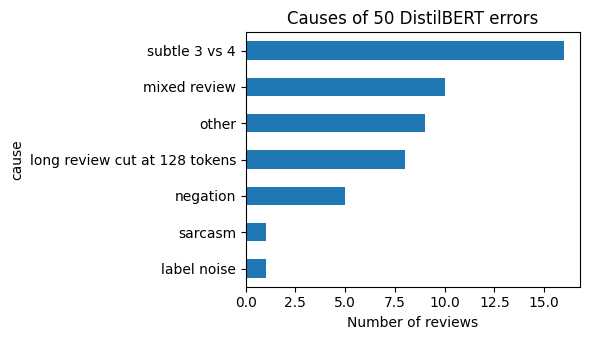

In [ ]:
best_preds = saved_preds[BEST_A].merge(test[["review_id", "text"]], on="review_id")
errors = best_preds[best_preds["y_true"] != best_preds["y_pred"]]
off_by_one = (abs(errors["y_true"] - errors["y_pred"]) == 1).mean()
print(f"{MODEL_NAMES[BEST_A]}: {len(errors)} errors of {len(best_preds)} | off by exactly one star: {off_by_one:.1%}")
print("errors by true star:")
print(errors["y_true"].value_counts().sort_index().to_string())

ERROR_BLANK = RESULTS + "/error_sample_50.csv"
ERROR_DONE = RESULTS + "/error_sample_50_labeled.csv"

if not os.path.exists(ERROR_BLANK):
    sample50 = errors.sample(min(50, len(errors)), random_state=SEED)[["review_id", "y_true", "y_pred", "text"]].copy()
    sample50["cause"] = ""
    sample50["n_words"] = sample50["text"].str.split().str.len()
    sample50.to_csv(ERROR_BLANK, index=False)

if os.path.exists(ERROR_DONE):
    causes = pd.read_csv(ERROR_DONE)["cause"].fillna("not labeled").str.strip().value_counts()
    causes.to_csv(RESULTS + "/error_causes.csv", header=["count"])
    causes.sort_values().plot(kind="barh", figsize=(6, 3.5), title="Causes of 50 " + MODEL_NAMES[BEST_A] + " errors")
    plt.xlabel("Number of reviews")
    plt.tight_layout()
    plt.savefig(FIGURES + "/error_causes.png", dpi=150)
    plt.show()
else:
    print("Causes not labeled yet: fill in", ERROR_BLANK, "and save it as", ERROR_DONE)

### 11.4 Limitations (for the report)

One short paragraph each, with one example and one number from the files:

1. **Label noise and subtle 3 vs 4 stars**: share of errors off by one star (11.3), `confident_mistakes.csv` (Appendix B).
2. **Sarcasm**: `task_a_negation_sarcasm.csv` (Appendix F).
3. **128-token limit for DistilBERT**: errors with `n_words` over about 100 in `error_sample_50.csv`.
4. **Domain shift SemEval → Yelp**: `task_b_sentiment.csv` vs `manual_100_scores.csv`.
5. **Small Atmosphere sample**: `task_b_pair_counts.csv`.
6. **Random vs restaurant split**: `task_a_classical.csv` (Appendix D).

---
# Part 12: Save the models and the Gradio demo

### 12.1 Save the classical models

In [ ]:
import joblib

joblib.dump({"detector": detector, "thresholds": THR, "lexicon": LEXICON, "best_detector": BEST_DETECTOR},
            MODELS + "/aspect_detector.joblib")
joblib.dump({"model": lr_sent, "clause_split": CLAUSE_SPLIT.pattern}, MODELS + "/aspect_sentiment_lr.joblib")
joblib.dump({"model": lr_model, "text_version": "t_neg", "weights": weights}, MODELS + "/task_a_lr.joblib")
print(sorted(os.listdir(MODELS)))

['aspect_detector.joblib', 'aspect_sentiment_lr.joblib', 'distilbert_aspect_detector', 'distilbert_b_ckpt_45', 'distilbert_task_a', 'distilbert_task_b', 'task_a_lr.joblib']


### 12.2 The demo (fixed in v6)

**The problem we found in v5.** For *"The food was great but the service was painfully slow."* the v5 demo said **Food = Negative**. The demo used DistilBERT for aspect sentiment, and DistilBERT reads the whole sentence at once. The negative half ("service was slow") pulled the Food answer down too. Part 10.4 shows the same thing in numbers: on the sentences that are positive about one aspect and negative about another, DistilBERT was right only 47% of the time and Logistic Regression 68%.

**The fix (demo only).**
1. Split each sentence into parts at contrast words: *but, however, although, though, yet, while, whereas*. So "The food was great but the service was slow" becomes "The food was great" and "the service was slow".
2. Find the aspects in **each part** (same detector as before), and score each part on its own.
3. Use the **TF-IDF + Logistic Regression** sentiment model from 10.2 for this, because it handled mixed sentences better.
4. Combine per aspect like before: Positive, Negative, Mixed or Not mentioned.

The star rating and the evaluation numbers in Parts 9 to 11 do not change. Only the demo uses the new function `demo_review_result()`. The next cell shows a few mixed sentences before (v5) and after (v6).


In [ ]:
# v6: split at contrast words, then find aspects and sentiment in each part
CONTRAST_SPLIT = re.compile(r"\s*(?:,\s*)?\b(?:but|however|although|though|yet|while|whereas)\b\s*,?\s*", re.I)


LEADING_CONTRAST = re.compile(r"^\s*(?:although|though|while|whereas)\b\s*([^,]+),\s*(.+)$", re.I)


def contrast_parts(sentence):
    # "The food was great but the service was slow" -> ["The food was great", "the service was slow"]
    # "Although the decor is nice, the food was bland" -> ["the decor is nice", "the food was bland"]
    start = LEADING_CONTRAST.match(sentence)
    if start:
        pieces = [start.group(1), start.group(2)]
    else:
        pieces = [sentence]
    parts = []
    for piece in pieces:
        for part in CONTRAST_SPLIT.split(piece):
            part = part.strip(" ,.;!?")
            if part:
                parts.append(part)
    # Too short pieces (like "Great") have no aspect on their own: then keep the whole sentence
    if len(parts) < 2:
        return [sentence]
    for part in parts:
        if len(part.split()) < 2:
            return [sentence]
    return parts


def demo_review_result(review):
    labels = {"Food Quality": [], "Service": [], "Atmosphere": []}
    for sentence in sent_tokenize(review):
        found_in_parts = set()
        for part in contrast_parts(sentence):
            for aspect in detect(part):
                labels[aspect].append(lr_sentiment([part], [aspect])[0])
                found_in_parts.add(aspect)
        # An aspect found in the whole sentence but in no single part: score it on the sentence
        for aspect in detect(sentence):
            if aspect not in found_in_parts:
                labels[aspect].append(lr_sentiment([sentence], [aspect])[0])

    result = {}
    for aspect in ASPECTS:
        found = labels[aspect]
        if len(found) == 0:
            result[aspect] = "Not mentioned"
        elif "positive" in found and "negative" in found:
            result[aspect] = "Mixed"
        elif "positive" in found:
            result[aspect] = "Positive"
        else:
            result[aspect] = "Negative"
    return result


for s in ["The food was great but the service was painfully slow.",
          "Although the waiter was rude, the pasta was amazing.",
          "Great but slow."]:
    print(repr(s), "->", contrast_parts(s))


In [ ]:
# Before (v5 demo) and after (v6 demo) on mixed sentences
mixed_tests = [
    "The food was great but the service was painfully slow.",
    "The pasta was delicious, however the waiter was rude.",
    "Although the decor is beautiful, the food was bland.",
    "Service was friendly and fast, but the music was way too loud.",
    "The sushi was fresh while the staff ignored us for 20 minutes.",
    "Lovely atmosphere, yet the steak was overcooked and the server was rude.",
]
rows = []
for text in mixed_tests:
    before = review_result(text)        # v5: sentence-level, BEST_SENT model
    after = demo_review_result(text)    # v6: contrast parts + Logistic Regression
    for aspect in ASPECTS:
        if before[aspect] != "Not mentioned" or after[aspect] != "Not mentioned":
            rows.append({"review": text, "aspect": aspect, "before (v5)": before[aspect], "after (v6)": after[aspect]})
mixed_compare = pd.DataFrame(rows)
mixed_compare.to_csv(RESULTS + "/demo_mixed_before_after.csv", index=False)
pd.set_option("display.max_colwidth", 80)
mixed_compare


In [ ]:
import gradio as gr

if os.path.exists(DB_A_PATH + "/config.json"):
    STAR_MODEL = "DistilBERT"
    demo_tokenizer = AutoTokenizer.from_pretrained(DB_A_PATH)
    demo_model = AutoModelForSequenceClassification.from_pretrained(DB_A_PATH).eval()

    def predict_stars(text):
        inputs = demo_tokenizer(text, truncation=True, max_length=128, return_tensors="pt")
        with torch.no_grad():
            proba = torch.softmax(demo_model(**inputs).logits, dim=1)[0].numpy()
        return int(proba.argmax()) + 1, float(proba.max())
else:
    STAR_MODEL = "Logistic Regression"

    def predict_stars(text):
        proba = lr_model.predict_proba([preprocess(text)])[0]
        return int(lr_model.classes_[proba.argmax()]), float(proba.max())


def analyze(review):
    if not review or not review.strip():
        return "Please paste a review.", []
    stars, confidence = predict_stars(review)
    aspects = demo_review_result(review)    # v6: mixed sentences fixed (see above)
    table = []
    for aspect in ASPECTS:
        table.append([aspect, aspects[aspect]])
    return f"{stars} stars (confidence {confidence:.0%}, {STAR_MODEL})", table


tests = ["Amazing food, friendly staff, lovely decor. Best dinner this year!",
         "The pasta was delicious and the waiter was so attentive.",
         "Great cozy atmosphere and the sushi was fresh.",
         "The soup was cold and the waiter was rude. Never again.",
         "Terrible service, we waited forever and the food was bland.",
         "Dirty tables, loud music and overpriced, tasteless food.",
         "The food was great but the service was painfully slow.",
         "The food was not good and the staff was not friendly.",
         " ".join(["We came here for a birthday and the food was good."] * 60),
         ""]
for text in tests:
    print(repr(text[:60]), "->", analyze(text))

if RUN_DEMO:
    demo = gr.Interface(fn=analyze, inputs=gr.Textbox(lines=6, label="Restaurant review"),
                        outputs=[gr.Text(label="Predicted stars"),
                                 gr.Dataframe(headers=["Aspect", "Result"], label="Aspects")],
                        title="ITM 454 - Restaurant review analyzer",
                        description=f"Stars: {STAR_MODEL}. Aspects: {BEST_DETECTOR} detector + Logistic Regression sentiment, sentences split at but / however / although.", examples=[[t] for t in tests[:8]])
    demo.launch(share=True)

---
# Part 13: Final tables and figures for the report

Everything here reads the files in `results/`, so the numbers in the report and in the files always match. Some files come from the Appendix: on the very first run they appear after the Appendix has run (re-run this part at the end).

In [ ]:
for file in ["task_a_raw_vs_clean.csv", "ablation_preprocessing.csv", "task_a_classical.csv", "task_a_comparison.csv",
             "task_b_detection.csv", "task_b_sentiment.csv", "human_vs_model.csv", "manual_100_scores.csv", "error_causes.csv"]:
    print("\n=====", file, "=====")
    if os.path.exists(RESULTS + "/" + file):
        print(pd.read_csv(RESULTS + "/" + file).round(3).to_string(index=False))
    else:
        print("not created yet")


===== task_a_raw_vs_clean.csv =====
              model train_data     test_set  n_test  accuracy  macro_f1   mae  within_1  acc_3class  macro_f1_3class  acc_binary
        Naive Bayes        raw     raw test   10000     0.624     0.568 0.456     0.946       0.850            0.738       0.918
        Naive Bayes        raw cleaned test    9998     0.624     0.567 0.456     0.946       0.850            0.738       0.918
        Naive Bayes    cleaned cleaned test    9998     0.620     0.566 0.460     0.946       0.847            0.734       0.916
Logistic Regression        raw     raw test   10000     0.638     0.592 0.422     0.955       0.855            0.744       0.921
Logistic Regression        raw cleaned test    9998     0.638     0.592 0.422     0.955       0.855            0.744       0.921
Logistic Regression    cleaned cleaned test    9998     0.640     0.594 0.422     0.955       0.857            0.752       0.919

===== ablation_preprocessing.csv =====
text_version  accura

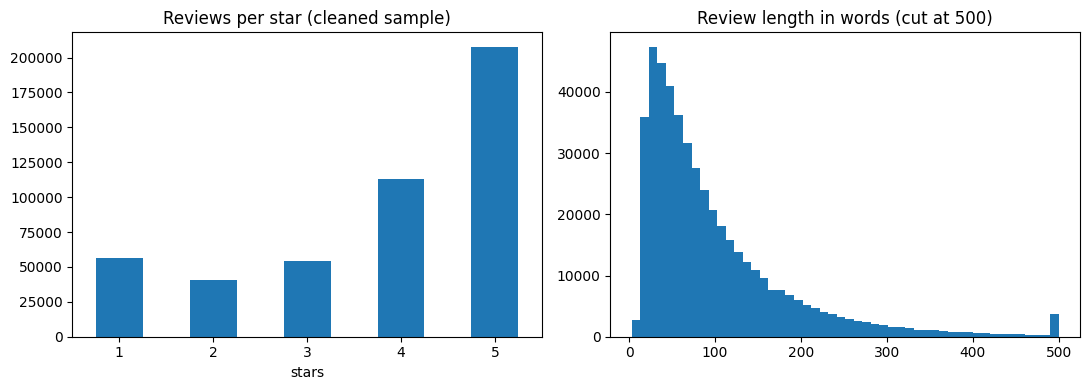

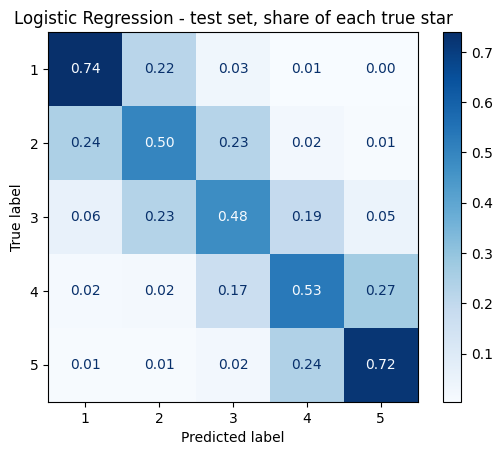

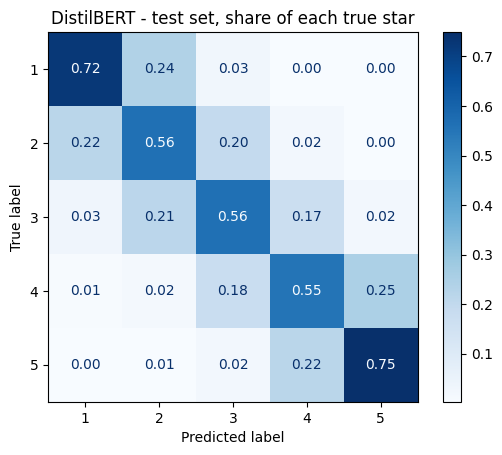

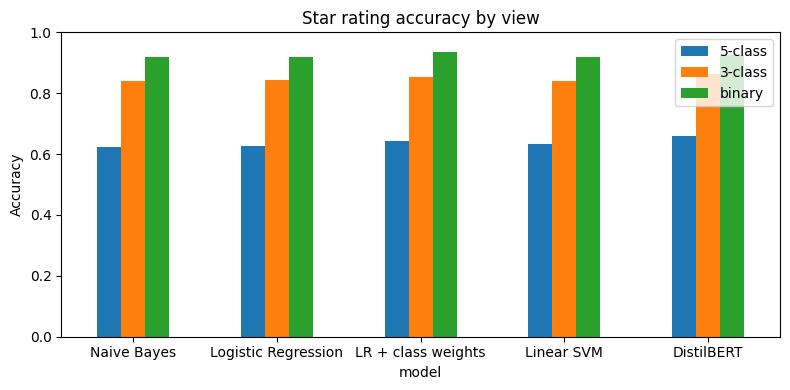

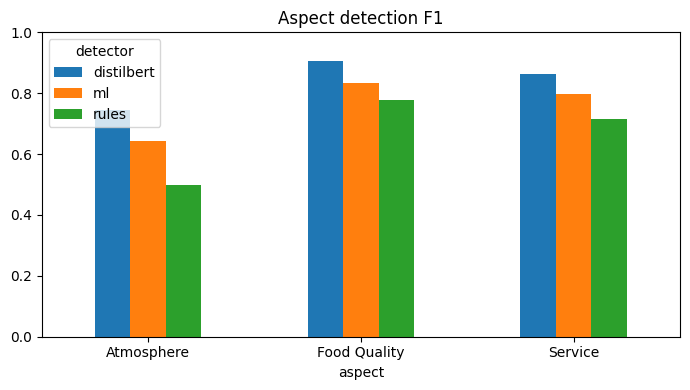

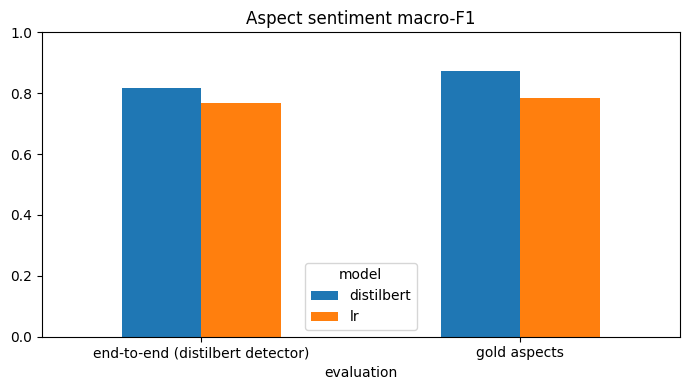

['confusion_distilbert.png', 'confusion_lr.png', 'data.png', 'error_causes.png', 'learning_curve.png', 'task_a_views.png', 'task_b_detection.png', 'task_b_sentiment.png']


In [ ]:
# 1. Reviews per star and review length
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df_clean["stars"].value_counts().sort_index().plot(kind="bar", ax=axes[0], rot=0, title="Reviews per star (cleaned sample)")
axes[1].hist(df_clean["text"].str.split().str.len().clip(upper=500), bins=50)
axes[1].set_title("Review length in words (cut at 500)")
plt.tight_layout()
plt.savefig(FIGURES + "/data.png", dpi=150)
plt.show()

# 2. Confusion matrices
for key in ["lr", "distilbert"]:
    if key in saved_preds:
        ConfusionMatrixDisplay.from_predictions(saved_preds[key]["y_true"], saved_preds[key]["y_pred"],
                                                normalize="true", values_format=".2f", cmap="Blues")
        plt.title(MODEL_NAMES[key] + " - test set, share of each true star")
        plt.savefig(FIGURES + "/confusion_" + key + ".png", dpi=150, bbox_inches="tight")
        plt.show()

# 3. 5-class, 3-class and binary accuracy
views = comparison[["accuracy", "acc_3class", "acc_binary"]]
views.columns = ["5-class", "3-class", "binary"]
views.plot(kind="bar", rot=0, figsize=(8, 4), ylim=(0, 1), title="Star rating accuracy by view")
plt.ylabel("Accuracy")
plt.tight_layout()
plt.savefig(FIGURES + "/task_a_views.png", dpi=150)
plt.show()

# 4. Aspect detection F1
d = det_results[(det_results["test_set"] == "20% hold-out") & det_results["aspect"].isin(ASPECTS)]
d.pivot(index="aspect", columns="detector", values="f1").plot(kind="bar", rot=0, figsize=(7, 4), ylim=(0, 1),
                                                               title="Aspect detection F1")
plt.tight_layout()
plt.savefig(FIGURES + "/task_b_detection.png", dpi=150)
plt.show()

# 5. Aspect sentiment: gold aspects vs end-to-end
s = sent_results[sent_results["aspect"] == "all"].pivot(index="evaluation", columns="model", values="macro_f1")
s.plot(kind="bar", rot=0, figsize=(7, 4), ylim=(0, 1), title="Aspect sentiment macro-F1")
plt.tight_layout()
plt.savefig(FIGURES + "/task_b_sentiment.png", dpi=150)
plt.show()
print(sorted(os.listdir(FIGURES)))

### Still to do outside the notebook

- GitHub repository and README: never commit `data/` or `models/`.
- Final report (Nov 29) and slides (Dec 7) from the tables and figures above.

---
# Appendix: extra experiments

These support the report and the answer to the professor, but the main results above do not need them. Set `RUN_APPENDIX = False` in Part 0 to stop *Run all* here.

| | What | File |
|---|---|---|
| A | The progress-update model: random split, TF-IDF + NB / LR, GloVe neural network | |
| B | Raw vs cleaned data, confident mistakes | `task_a_raw_vs_clean.csv`, `confident_mistakes.csv` |
| C | Which preprocessing helps? (lemmatization, negation tagging) | `ablation_preprocessing.csv` |
| D | Random split vs restaurant split | `task_a_classical.csv` |
| E | Is it the data or the task? Learning curve and easier versions of the task | `learning_curve.csv`, `task_a_dedicated_views.csv` |
| F | Negation and sarcasm: Logistic Regression vs DistilBERT | `task_a_negation_sarcasm.csv` |
| G | The old ABSA sentiment model (v2) | `task_b_sentiment.csv` |
| H | ABSA examples and errors | `task_b_errors.csv` |

In [ ]:
if not RUN_APPENDIX:
    raise SystemExit("RUN_APPENDIX = False: Run all stops here (this is not an error).")

## A. The progress-update model (random split, GloVe neural network)

The code from our progress update, unchanged in its steps: a **random** train / validation / test split of the raw reviews, simple preprocessing, TF-IDF + Naive Bayes / Logistic Regression, and the neural network with GloVe embeddings from class.

#### A.1 Random split

In [ ]:
test_df = df.sample(EVAL_SIZE, random_state=45)
rest = df.drop(test_df.index)

val_df = rest.sample(EVAL_SIZE, random_state=45)
rest = rest.drop(val_df.index)

train_df = rest.groupby("stars", group_keys=False).sample(TRAIN_PER_STAR, random_state=45)

split_table = pd.DataFrame({"train": train_df["stars"].value_counts().sort_index(),
                            "validation": val_df["stars"].value_counts().sort_index(),
                            "test": test_df["stars"].value_counts().sort_index()})
split_table.loc["total"] = split_table.sum()
print(split_table)

        train  validation   test
stars                           
1       20000        1192   1196
2       20000         853    852
3       20000        1140   1092
4       20000        2431   2457
5       20000        4384   4403
total  100000       10000  10000


We convert the tables to Hugging Face `Dataset` objects (like `load_dataset()` in class). The label is the number of stars **minus 1**, so the 5 classes are 0, 1, 2, 3, 4.

In [ ]:
def to_dataset(data):
    data = data.reset_index(drop=True)
    return Dataset.from_dict({"text": data["text"].tolist(),
                              "label": (data["stars"] - 1).tolist()})

train_data = to_dataset(train_df)
val_data = to_dataset(val_df)
test_data = to_dataset(test_df)

label_names = ["1 star", "2 stars", "3 stars", "4 stars", "5 stars"]
print(train_data)

Dataset({
    features: ['text', 'label'],
    num_rows: 100000
})


#### A.2 Preprocessing (progress-update version)

Lowercase, remove punctuation and numbers, tokenize, remove stopwords; keep *not, no, nor, very*, and turn `n't` into `not` first.

In [ ]:
stop_words = set(stopwords.words("english")) - {"no", "nor", "not", "very"}

def preprocess_text(text):
    # Convert to lowercase
    text = text.lower()

    # "wasn't" -> "was not" (keep the negation)
    text = text.replace("n't", " not")

    # Replace numbers and special characters with a space
    text = re.sub(r"[^a-z\s]", " ", text)

    # Tokenize
    tokens = word_tokenize(text)

    # Remove stopwords
    tokens = [token for token in tokens if token not in stop_words]

    return tokens   # a list of words

def add_tokens(example):
    return {"tokens": preprocess_text(example["text"])}

train_data = train_data.map(add_tokens)
val_data = val_data.map(add_tokens)
test_data = test_data.map(add_tokens)

Map:   0%|          | 0/100000 [00:00<?, ? examples/s]

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

#### A.3 TF-IDF + Naive Bayes / Logistic Regression

In [ ]:
train_text = [" ".join(tokens) for tokens in train_data["tokens"]]
val_text = [" ".join(tokens) for tokens in val_data["tokens"]]
test_text = [" ".join(tokens) for tokens in test_data["tokens"]]

y_train = np.array(train_data["label"])
y_val = np.array(val_data["label"])
y_test = np.array(test_data["label"])

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=50000)
X_train = tfidf.fit_transform(train_text)   # fit on train only
X_val = tfidf.transform(val_text)
X_test = tfidf.transform(test_text)

nb_baseline = MultinomialNB().fit(X_train, y_train)
lr_baseline = LogisticRegression(max_iter=1000).fit(X_train, y_train)

#### A.4 Vocabulary, GloVe embeddings and DataLoader

In [ ]:
import gensim.downloader as api
from torch.utils.data import DataLoader
import torch.nn as nn

word_counts = Counter(word for tokens in train_data["tokens"] for word in tokens)
vocab = ["<pad>", "<unk>"] + [word for word, count in word_counts.items() if count >= 5]
word2idx = {word: i for i, word in enumerate(vocab)}
vocab_size = len(vocab)
print(f"Vocabulary size: {vocab_size}")

glove = api.load("glove-wiki-gigaword-100")   # downloads once (~130 MB)
embedding_size = 100
embedding_matrix = np.zeros((vocab_size, embedding_size), dtype=np.float32)
found = 0
for word, idx in word2idx.items():
    if word in glove:
        embedding_matrix[idx] = glove[word]
        found += 1
print(f"Words found in GloVe: {found} ({found / vocab_size:.1%})")

max_len = 100

def encode(example):
    ids = [word2idx.get(word, word2idx["<unk>"]) for word in example["tokens"]]
    ids = ids[:max_len]                                     # cut
    ids = ids + [word2idx["<pad>"]] * (max_len - len(ids))  # pad
    return {"input_ids": ids}

train_data = train_data.map(encode)
val_data = val_data.map(encode)
test_data = test_data.map(encode)

columns = ["input_ids", "label"]
train_data = train_data.with_format("torch", columns=columns)
val_data = val_data.with_format("torch", columns=columns)
test_data = test_data.with_format("torch", columns=columns)

batch_size = 64
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_data, batch_size=batch_size)
test_loader = DataLoader(test_data, batch_size=batch_size)

Vocabulary size: 21831
[==================================================] 100.0% 128.1/128.1MB downloaded
Words found in GloVe: 20541 (94.1%)


Map:   0%|          | 0/100000 [00:00<?, ? examples/s]

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

#### A.5 The neural network (same as in class, 5 outputs)

```
word IDs (100 per review)
   ↓  embedding layer (GloVe)        each word → 100 numbers
   ↓  average the word vectors       one review → 100 numbers
   ↓  hidden layer + ReLU            100 → 64 numbers
   ↓  output layer                   64 → 5 scores (one per star)
```

In [ ]:
class TextClassifier(nn.Module):
    def __init__(self, embedding_matrix, num_classes, freeze=True):
        super().__init__()
        embedding_size = embedding_matrix.shape[1]
        self.embedding = nn.Embedding.from_pretrained(torch.tensor(embedding_matrix), freeze=freeze, padding_idx=0)
        self.hidden = nn.Linear(embedding_size, 64)
        self.relu = nn.ReLU()
        self.output = nn.Linear(64, num_classes)

    def forward(self, input_ids):
        vectors = self.embedding(input_ids)                  # (batch, 100, 100)
        mask = (input_ids != 0).unsqueeze(-1).float()        # 1 = real word, 0 = padding
        review = (vectors * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        h = self.relu(self.hidden(review))
        return self.output(h)


torch.manual_seed(45)
nn_model = TextClassifier(embedding_matrix, num_classes=5)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(nn_model.parameters(), lr=0.001)

def evaluate(model, loader):
    model.eval()
    total_loss, correct = 0, 0
    with torch.no_grad():
        for batch in loader:
            scores = model(batch["input_ids"])
            total_loss += loss_fn(scores, batch["label"]).item() * len(batch["label"])
            correct += (scores.argmax(dim=1) == batch["label"]).sum().item()
    return total_loss / len(loader.dataset), correct / len(loader.dataset)

history = {"train_loss": [], "val_loss": [], "val_acc": []}
for epoch in range(10):
    nn_model.train()
    total_loss = 0
    for batch in train_loader:
        scores = nn_model(batch["input_ids"])          # 1. predict (forward propagation)
        loss = loss_fn(scores, batch["label"])         # 2. compute the loss
        optimizer.zero_grad()                          # 3. clear old gradients
        loss.backward()                                # 4. compute gradients (backward propagation)
        optimizer.step()                               # 5. update the weights
        total_loss += loss.item()
    val_loss, val_acc = evaluate(nn_model, val_loader)
    history["train_loss"].append(total_loss / len(train_loader))
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    print(f"Epoch {epoch + 1:2d} | train loss = {history['train_loss'][-1]:.4f} | val loss = {val_loss:.4f} | val accuracy = {val_acc:.1%}")

Epoch  1 | train loss = 1.2541 | val loss = 1.1724 | val accuracy = 49.9%
Epoch  2 | train loss = 1.1716 | val loss = 1.1123 | val accuracy = 53.9%
Epoch  3 | train loss = 1.1599 | val loss = 1.0717 | val accuracy = 54.8%
Epoch  4 | train loss = 1.1535 | val loss = 1.1580 | val accuracy = 51.1%
Epoch  5 | train loss = 1.1488 | val loss = 1.0846 | val accuracy = 52.8%
Epoch  6 | train loss = 1.1448 | val loss = 1.0612 | val accuracy = 55.7%
Epoch  7 | train loss = 1.1423 | val loss = 1.0692 | val accuracy = 53.8%
Epoch  8 | train loss = 1.1390 | val loss = 1.1446 | val accuracy = 52.1%
Epoch  9 | train loss = 1.1362 | val loss = 1.0994 | val accuracy = 53.5%
Epoch 10 | train loss = 1.1335 | val loss = 1.0947 | val accuracy = 53.3%


#### A.6 Results of the progress-update models (random split, test set)

In [ ]:
def get_predictions(model, loader):
    model.eval()
    predictions = []
    with torch.no_grad():
        for batch in loader:
            predictions.extend(model(batch["input_ids"]).argmax(dim=1).tolist())
    return np.array(predictions)

nn_pred = get_predictions(nn_model, test_loader)

# score() uses stars 1-5, the labels here are 0-4, so add 1
progress_results = pd.DataFrame([score(y_test + 1, nb_baseline.predict(X_test) + 1, "Naive Bayes"),
                                 score(y_test + 1, lr_baseline.predict(X_test) + 1, "Logistic Regression"),
                                 score(y_test + 1, nn_pred + 1, "Neural Network (GloVe)")])
progress_results.round(3)

,model,accuracy,macro_f1,mae,within_1,acc_3class,macro_f1_3class,acc_binary
0,Naive Bayes,0.624,0.568,0.455,0.946,0.850,0.737,0.918
1,Logistic Regression,0.638,0.591,0.422,0.955,0.857,0.746,0.922
2,Neural Network (GloVe),0.522,0.472,0.638,0.886,0.759,0.645,0.836


## B. Raw vs cleaned data (for the professor)

Same random split and same preprocessing as Appendix A, so the only thing that changes is the cleaning of Part 2. The raw models are scored on the raw test set **and** on the cleaned test set, to separate "the test got easier" from "the model got better". Test and validation keep the same reviews, minus the ones the cleaning dropped.

In [ ]:
clean_by_id = df_clean.set_index("review_id")["text"]

def cleaned(part):
    # The same reviews, with their cleaned text (reviews dropped by the cleaning are removed)
    part = part[part["review_id"].isin(clean_by_id.index)].copy()
    part["text"] = part["review_id"].map(clean_by_id)
    return part

pool_c = cleaned(df.drop(test_df.index).drop(val_df.index))
test_c = cleaned(test_df)
val_c = cleaned(val_df)
train_c = pool_c.groupby("stars", group_keys=False).sample(TRAIN_PER_STAR, random_state=SEED)
print("test reviews before / after cleaning:", len(test_df), len(test_c))


def joined_tokens(part):
    return [" ".join(preprocess_text(text)) for text in part["text"]]


def fit_nb_lr(part):
    vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=50000)
    X = vectorizer.fit_transform(joined_tokens(part))
    nb = MultinomialNB().fit(X, part["stars"])
    lr = LogisticRegression(max_iter=1000).fit(X, part["stars"])
    return vectorizer, nb, lr


vec_raw, nb_raw, lr_raw = fit_nb_lr(train_df)
vec_c, nb_c, lr_c = fit_nb_lr(train_c)
X_test_raw = vec_raw.transform(joined_tokens(test_df))
X_test_c_rawvec = vec_raw.transform(joined_tokens(test_c))
X_test_c = vec_c.transform(joined_tokens(test_c))

rows = []
for name, model_raw, model_c in [("Naive Bayes", nb_raw, nb_c), ("Logistic Regression", lr_raw, lr_c)]:
    row = score(test_df["stars"], model_raw.predict(X_test_raw), name)
    rows.append({"train_data": "raw", "test_set": "raw test", "n_test": len(test_df), **row})
    row = score(test_c["stars"], model_raw.predict(X_test_c_rawvec), name)
    rows.append({"train_data": "raw", "test_set": "cleaned test", "n_test": len(test_c), **row})
    row = score(test_c["stars"], model_c.predict(X_test_c), name)
    rows.append({"train_data": "cleaned", "test_set": "cleaned test", "n_test": len(test_c), **row})
raw_vs_clean = pd.DataFrame(rows)[["model", "train_data", "test_set", "n_test"] + COLS]
raw_vs_clean.to_csv(RESULTS + "/task_a_raw_vs_clean.csv", index=False)
raw_vs_clean.round(3)

test reviews before / after cleaning: 10000 9998


,model,train_data,test_set,n_test,accuracy,macro_f1,mae,within_1,acc_3class,macro_f1_3class,acc_binary
0,Naive Bayes,raw,raw test,10000,0.624,0.568,0.455,0.946,0.850,0.737,0.918
1,Naive Bayes,raw,cleaned test,9998,0.624,0.567,0.455,0.946,0.850,0.737,0.918
2,Naive Bayes,cleaned,cleaned test,9998,0.621,0.566,0.460,0.946,0.847,0.734,0.916
3,Logistic Regression,raw,raw test,10000,0.638,0.591,0.422,0.955,0.857,0.746,0.922
4,Logistic Regression,raw,cleaned test,9998,0.638,0.592,0.422,0.955,0.857,0.747,0.922
5,Logistic Regression,cleaned,cleaned test,9998,0.639,0.592,0.422,0.955,0.857,0.749,0.920


**Confident mistakes.** Test reviews where the cleaned LR gave 80%+ to one star and was still wrong, most confident first. Many are **label noise** (the text says one thing, the stars another).

In [ ]:
proba_c = lr_c.predict_proba(X_test_c)
mistakes = test_c.copy()
mistakes["pred"] = lr_c.classes_[proba_c.argmax(axis=1)]
mistakes["confidence"] = proba_c.max(axis=1)
mistakes = mistakes[(mistakes["pred"] != mistakes["stars"]) & (mistakes["confidence"] >= 0.8)]
mistakes = mistakes.sort_values("confidence", ascending=False)
mistakes[["review_id", "stars", "pred", "confidence", "text"]].to_csv(RESULTS + "/confident_mistakes.csv", index=False)

print(len(mistakes), "confident mistakes out of", len(test_c))
for index, row in mistakes.head(20).iterrows():
    print(f"true {row['stars']} | pred {row['pred']} ({row['confidence']:.0%}) | {row['text'][:300]!r}\n")

156 confident mistakes out of 9998
true 4 | pred 5 (96%) | 'My family and I moved here a few months ago and Rams has become a favorite! Not only is the food amazing but the service is ALWAYS SPECTACULAR! I highly recommend eating here ( know at any point you will wait for a table, no need to get upset, it will be well worth the wait!)'

true 2 | pred 1 (95%) | "I just experienced an annoying series of events with Allegro's Pizza. Sunday night (5/31/2009) we placed a delivery order, which we do about once a week. One of the items we ordered was chicken fingers. When they arrived, my partner opened up the chicken container and recoiled at the smell. I sniffe"

true 4 | pred 5 (95%) | 'i asked a local friend where her go-to BBQ is, and she immediately said B&C. fast, friendly service and piping hot, delicious BBQ with all the amazing fixins. there are too many to choose from (as happens), but i definitely recommend the bevy of grits choices. the buffalo grits are absolutely amazin'

true 

## C. Which preprocessing helps?

The same Logistic Regression on four versions of the text, scored on the **validation** set: plain, lemmatization, negation tagging, both. Negation tagging alone (`neg`) had the best macro-F1, so Part 4 uses it. Takes 5 to 10 minutes.

In [ ]:
VERSIONS = {"plain": (False, False), "lemma": (False, True), "neg": (True, False), "lemma+neg": (True, True)}

rows = []
for version in VERSIONS:
    use_neg, use_lemma = VERSIONS[version]
    train_version = [preprocess(text, use_neg, use_lemma) for text in train["text"]]
    val_version = [preprocess(text, use_neg, use_lemma) for text in val["text"]]
    pipe = Pipeline([("tfidf", make_tfidf()), ("clf", LogisticRegression(max_iter=1000))])
    pipe.fit(train_version, train["stars"])
    row = score(val["stars"], pipe.predict(val_version), "lr")
    row["text_version"] = version
    rows.append(row)
    print(version, "done")

ablation = pd.DataFrame(rows)[["text_version"] + COLS]
ablation.to_csv(RESULTS + "/ablation_preprocessing.csv", index=False)
ablation.round(4)

plain done
lemma done
neg done
lemma+neg done


,text_version,accuracy,macro_f1,mae,within_1,acc_3class,macro_f1_3class,acc_binary
0,plain,0.6308,0.5851,0.4471,0.9462,0.8434,0.7364,0.9116
1,lemma,0.6279,0.5808,0.4491,0.9455,0.8431,0.7359,0.9123
2,neg,0.6321,0.5862,0.4425,0.9484,0.8454,0.7375,0.9137
3,lemma+neg,0.6350,0.5868,0.4400,0.9481,0.8467,0.7386,0.9152


## D. Random split vs restaurant split

The tuned models of Part 5, trained and tested on the **random** split of Appendix B (cleaned). The random split is easier, because reviews of the same restaurant are in train and test. The rows are added to `task_a_classical.csv`.

In [ ]:
train_c["clean_text"] = [preprocess(text) for text in train_c["text"]]
test_c["clean_text"] = [preprocess(text) for text in test_c["text"]]

rows = []
for name, classifier in [("Naive Bayes", MultinomialNB(alpha=nb_alpha)),
                         ("Logistic Regression", LogisticRegression(C=lr_C, max_iter=1000)),
                         ("Linear SVM", LinearSVC(C=svm_C))]:
    pipe = Pipeline([("tfidf", make_tfidf()), ("clf", classifier)])
    pipe.fit(train_c["clean_text"], train_c["stars"])
    row = score(test_c["stars"], pipe.predict(test_c["clean_text"]), name)
    row["split"] = "random"
    rows.append(row)

classical_both = pd.concat([classical, pd.DataFrame(rows)])[["model", "split"] + COLS]
classical_both.to_csv(RESULTS + "/task_a_classical.csv", index=False)
classical_both.round(3)

,model,split,accuracy,macro_f1,mae,within_1,acc_3class,macro_f1_3class,acc_binary
0,Naive Bayes,restaurant,0.622,0.571,0.454,0.944,0.839,0.726,0.920
1,Logistic Regression,restaurant,0.628,0.581,0.438,0.952,0.843,0.732,0.920
2,Linear SVM,restaurant,0.634,0.579,0.438,0.948,0.841,0.726,0.920
0,Naive Bayes,random,0.624,0.569,0.454,0.947,0.848,0.733,0.918
1,Logistic Regression,random,0.639,0.592,0.430,0.950,0.853,0.746,0.915
2,Linear SVM,random,0.645,0.588,0.425,0.949,0.855,0.742,0.922


## E. Is it the data or the task?

1. **Learning curve**: Logistic Regression trained on more and more reviews (scored on the validation set). If the score stops rising early, more data will not reach 80%. Saved in `learning_curve.csv` and reused in the next runs.
2. **Easier versions of the task**: models trained for 3 classes, for positive vs negative (3 stars left out), and for 1 star vs 5 stars. If these are high, the models do learn sentiment; the 5-star scale is what is hard.

Learning curve from an earlier run.
 train_size  accuracy  macro_f1  acc_3class  acc_binary
       5000     0.581     0.525       0.806       0.884
      12500     0.603     0.549       0.824       0.896
      25000     0.617     0.565       0.834       0.904
      50000     0.629     0.579       0.842       0.909
     100000     0.638     0.590       0.847       0.914
     162020     0.642     0.597       0.852       0.914


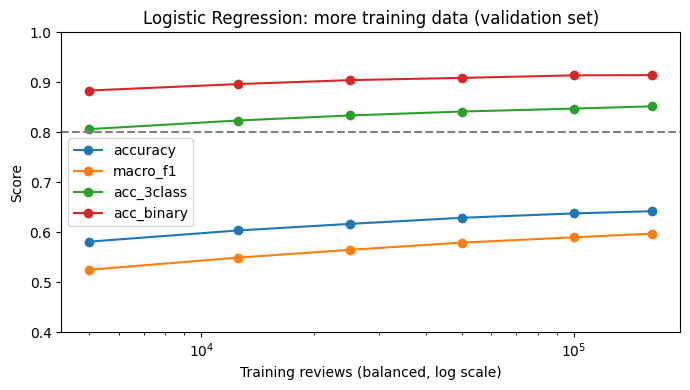

In [ ]:
LC_FILE = RESULTS + "/learning_curve.csv"

if os.path.exists(LC_FILE):
    learning = pd.read_csv(LC_FILE)
    print("Learning curve from an earlier run.")
else:
    pool_train = df_clean[df_clean["business_id"].isin(train_ids)]
    max_per_star = int(pool_train["stars"].value_counts().min())
    sizes = [1000, 2500, 5000, 10000, 20000]
    if QUICK:
        sizes = [200, 500, 1000, 2000]
    sizes = [size for size in sizes if size < max_per_star] + [max_per_star]   # last = all 2-star reviews

    big = pool_train.groupby("stars", group_keys=False).sample(sizes[-1], random_state=SEED).sample(frac=1, random_state=SEED)
    big["pp"] = [preprocess(text) for text in big["text"]]
    rows = []
    for size in sizes:
        subset = big.groupby("stars", group_keys=False).head(size)      # the first `size` reviews of each star
        pipe = Pipeline([("tfidf", make_tfidf()), ("clf", LogisticRegression(C=lr_C, max_iter=1000))])
        pipe.fit(subset["pp"], subset["stars"])
        row = score(val["stars"], pipe.predict(val["clean_text"]), "lr")
        row["reviews_per_star"] = size
        row["train_size"] = len(subset)
        rows.append(row)
        print(f"{len(subset):>7,} training reviews: accuracy {row['accuracy']:.3f} | macro-F1 {row['macro_f1']:.3f}")
    learning = pd.DataFrame(rows).drop(columns="model")
    learning.to_csv(LC_FILE, index=False)

print(learning[["train_size", "accuracy", "macro_f1", "acc_3class", "acc_binary"]].round(3).to_string(index=False))
learning.plot(x="train_size", y=["accuracy", "macro_f1", "acc_3class", "acc_binary"], marker="o", logx=True,
              figsize=(7, 4), ylim=(0.4, 1.0), title="Logistic Regression: more training data (validation set)")
plt.axhline(0.8, linestyle="--", color="grey")
plt.xlabel("Training reviews (balanced, log scale)")
plt.ylabel("Score")
plt.tight_layout()
plt.savefig(FIGURES + "/learning_curve.png", dpi=150)
plt.show()

In [ ]:
def train_and_test(view_name, train_mask, y_train_view, test_mask, y_test_view):
    pipe = Pipeline([("tfidf", make_tfidf()),
                     ("clf", LogisticRegression(C=lr_C, max_iter=1000, class_weight="balanced"))])
    pipe.fit(train["clean_text"][train_mask], y_train_view)
    pred = pipe.predict(test["clean_text"][test_mask])
    return {"view": view_name, "n_test": int(test_mask.sum()),
            "accuracy": accuracy_score(y_test_view, pred), "macro_f1": f1_score(y_test_view, pred, average="macro")}


all_train = np.ones(len(train), dtype=bool)
all_test = np.ones(len(test), dtype=bool)
no3_train = (train["stars"] != 3).values
no3_test = (test["stars"] != 3).values
ext_train = train["stars"].isin([1, 5]).values
ext_test = test["stars"].isin([1, 5]).values

rows = []
rows.append({"view": "5 classes (best model, from 4.1 / 3.4)", "n_test": len(test),
             "accuracy": accuracy_score(test["stars"], preds["lr_weighted"]),
             "macro_f1": f1_score(test["stars"], preds["lr_weighted"], average="macro")})
rows.append(train_and_test("3 classes (neg / neutral / pos)", all_train, to_3_classes(train["stars"]),
                           all_test, to_3_classes(test["stars"])))
rows.append(train_and_test("binary (1-2 vs 4-5, no 3 stars)", no3_train, train["stars"][no3_train] >= 4,
                           no3_test, test["stars"][no3_test] >= 4))
rows.append(train_and_test("1 star vs 5 stars only", ext_train, train["stars"][ext_train] == 5,
                           ext_test, test["stars"][ext_test] == 5))
dedicated = pd.DataFrame(rows)
dedicated.to_csv(RESULTS + "/task_a_dedicated_views.csv", index=False)
dedicated.round(3)

,view,n_test,accuracy,macro_f1
0,"5 classes (best model, from 4.1 / 3.4)",10000,0.644,0.588
1,3 classes (neg / neutral / pos),10000,0.834,0.740
2,"binary (1-2 vs 4-5, no 3 stars)",8809,0.959,0.944
3,1 star vs 5 stars only,5519,0.973,0.961


## F. Negation and sarcasm: Logistic Regression vs DistilBERT

Our proposal expects DistilBERT to do better on reviews with negation or sarcasm. We test that, and print reviews where the two models disagree.

In [ ]:
if "distilbert" in saved_preds:
    both = saved_preds["lr"].merge(saved_preds["distilbert"], on=["review_id", "y_true"], suffixes=("_lr", "_db"))
    both = both.merge(test[["review_id", "text"]], on="review_id")
    has_negation = both["text"].str.contains(r"\b(?:not|no|never|nothing|hardly)\b|n't\b", case=False, regex=True)
    has_sarcasm = both["text"].str.contains(r"yeah right|oh great|thanks for nothing|so-called|what a joke|just perfect",
                                            case=False, regex=True)
    rows = []
    for name, mask in [("all test", pd.Series(True, index=both.index)), ("with negation", has_negation),
                       ("sarcasm cues", has_sarcasm)]:
        subset = both[mask]
        if len(subset) == 0:
            continue
        rows.append({"subset": name, "n": len(subset),
                     "lr_acc": (subset["y_pred_lr"] == subset["y_true"]).mean(),
                     "distilbert_acc": (subset["y_pred_db"] == subset["y_true"]).mean(),
                     "lr_macro_f1": f1_score(subset["y_true"], subset["y_pred_lr"], average="macro"),
                     "distilbert_macro_f1": f1_score(subset["y_true"], subset["y_pred_db"], average="macro")})
    negation_table = pd.DataFrame(rows)
    negation_table.to_csv(RESULTS + "/task_a_negation_sarcasm.csv", index=False)
    display(negation_table.round(3))

    for title, mask in [("LR wrong, DistilBERT right", (both["y_pred_lr"] != both["y_true"]) & (both["y_pred_db"] == both["y_true"])),
                        ("DistilBERT wrong, LR right", (both["y_pred_db"] != both["y_true"]) & (both["y_pred_lr"] == both["y_true"]))]:
        print(f"\n--- {title}: {mask.sum()} reviews")
        for index, row in both[mask].head(10).iterrows():
            print(f"  true {row['y_true']} | LR {row['y_pred_lr']} | DB {row['y_pred_db']} | {row['text'][:200]!r}")
else:
    print("No DistilBERT predictions yet.")

,subset,n,lr_acc,distilbert_acc,lr_macro_f1,distilbert_macro_f1
0,all test,10000,0.628,0.660,0.581,0.619
1,with negation,6418,0.601,0.625,0.582,0.610
2,sarcasm cues,16,0.688,0.625,0.536,0.486



--- LR wrong, DistilBERT right: 1399 reviews
  true 1 | LR 2 | DB 1 | 'Has gone so far downhill. Emeril should be embarrassed. Table and glassware were dirty. Service not great. Presentation of food poor. And cobb salad inedible. Used to be good but no longer.'
  true 5 | LR 3 | DB 5 | "My Cousin who came from Shanghai told me it is so good! She asked me to rate the resturant 5 stars since she doesn't have a Yelp account!"
  true 5 | LR 4 | DB 5 | "Even after several years, the food is still just as good as I remember. I usually get the teppan chicken with extra sauce and gorge myself on it. It's excellent and really cheap as well. The atmospher"
  true 4 | LR 5 | DB 4 | "Visited this resturaunt last night. I never knew it was there because it's tucked away on the side a shopping strip away from street view. I wish I knew about this place sooner. They have plenty vegan"
  true 4 | LR 5 | DB 4 | "Saturday evening 7pm. They keep the line moving, portions are consistent, in and out. My n

## G. The old ABSA sentiment model (v2)

One Logistic Regression per aspect, on the whole sentence, SemEval-2014 only. Kept to show what the improvements in Part 10 (shared model, more data, aspect part of the sentence) bring. Its rows are added to `task_b_sentiment.csv` as `lr_v2`.

In [ ]:
pairs_train_2014 = make_pairs(sem_train)
lr_per_aspect = {}
for aspect in ASPECTS:
    data = pairs_train_2014[pairs_train_2014["aspect"] == aspect]
    search = GridSearchCV(Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=1)),
                                    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000))]),
                          {"clf__C": [0.3, 1, 3, 10]}, scoring="f1_macro",
                          cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
    search.fit(data["text"], data["label"])
    lr_per_aspect[aspect] = search.best_estimator_


def lr_v2_sentiment(texts, aspects):
    texts = list(texts)
    aspects = list(aspects)
    result = []
    for text, aspect in zip(texts, aspects):
        result.append(lr_per_aspect[aspect].predict([text])[0])
    return np.array(result, dtype=object)


sent_results_all = pd.concat([pd.DataFrame(evaluate_sentiment("lr_v2", lr_v2_sentiment)), sent_results])
sent_results_all.to_csv(RESULTS + "/task_b_sentiment.csv", index=False)
sent_results_all.pivot_table(index=["evaluation", "aspect"], columns="model", values="macro_f1", sort=False).round(3)

model                                          lr_v2     lr  distilbert
evaluation                       aspect                                
gold aspects                     Food Quality  0.746  0.717       0.918
                                 Service       0.778  0.833       0.840
                                 Atmosphere    0.742  0.799       0.800
                                 all           0.771  0.784       0.874
end-to-end (distilbert detector) Food Quality  0.761  0.737       0.851
                                 Service       0.760  0.798       0.794
                                 Atmosphere    0.691  0.746       0.726
                                 all           0.757  0.769       0.818

## H. ABSA examples and errors

First, sentences where the rules and the TF-IDF detector disagree. Then every error of the pipeline on the test sentences (missed aspect, false alarm, wrong sentiment), with a few possible causes: *but* in the sentence, an indirect mention, price words, sarcasm.

In [ ]:
rule_pred = rule_detect(sem_test["text"])
ml_pred = ml_detect(sem_test["text"])
gold = aspect_matrix(sem_test)

for title, mask in [("ML right, rules wrong", (ml_pred == gold).all(axis=1) & (rule_pred != gold).any(axis=1)),
                    ("rules right, ML wrong", (rule_pred == gold).all(axis=1) & (ml_pred != gold).any(axis=1))]:
    print(f"--- {title}: {mask.sum()} sentences")
    for i in np.where(mask)[0][:5]:
        gold_aspects = [aspect for aspect, value in zip(ASPECTS, gold[i]) if value == 1]
        print("   gold =", gold_aspects or ["none"], "|", sem_test["text"].iloc[i])

--- ML right, rules wrong: 121 sentences
   gold = ['Food Quality', 'Atmosphere'] | They need a kick out of it but until then the sushi is pretty good and the place is consistent.
   gold = ['Service'] | This is a great Thai restaurant with a very friendly staff.
   gold = ['Food Quality'] | The portion sizes here are huge, and the sushi is good.
   gold = ['Food Quality'] | They smell like they stuff them with old canned vegetables like the spinach mushroom calzone.
   gold = ['Service'] | I like Cafe Noir dont get me wrong, it is jsut that the people who work there are evil and incompetent!!
--- rules right, ML wrong: 46 sentences
   gold = ['Food Quality', 'Service'] | The food always tastes fresh and served promptly.
   gold = ['Food Quality', 'Service'] | The portions are now very small, the sauces are overly-ambitious usually inedible while the service is still good, the restaurant, due to its popularity, seems frantic.
   gold = ['Food Quality', 'Service', 'Atmosphere'] | The fo

In [ ]:
detected = DETECTORS[BEST_DETECTOR](sem_test["text"])
rows = []
for k, aspect in enumerate(ASPECTS):
    for i in range(len(sem_test)):
        text = sem_test["text"].iloc[i]
        gold_label = sem_test[aspect].iloc[i]
        if gold[i, k] == 1 and detected[i, k] == 0:
            kind = "missed aspect"
        elif detected[i, k] == 1 and gold[i, k] == 0:
            kind = "false alarm"
        elif detected[i, k] == 1 and gold_label in ("positive", "negative") and sentiment(text, aspect) != gold_label:
            kind = "wrong polarity"
        else:
            continue
        rows.append({"aspect": aspect, "error": kind, "text": text, "gold": gold_label,
                     "has_but": bool(re.search(r"\bbut\b", text, re.I)),
                     "indirect": len(ngrams(text) & LEXICON[aspect]) == 0,
                     "price_words": bool(re.search(r"\b(price|prices|pricey|expensive|cheap|overpriced|\$)", text, re.I)),
                     "sarcasm_cue": bool(re.search(r"yeah right|oh great|thanks for nothing|what a joke", text, re.I))})
absa_errors = pd.DataFrame(rows)
absa_errors.to_csv(RESULTS + "/task_b_errors.csv", index=False)
display(absa_errors.groupby(["aspect", "error"]).agg(n=("text", "size"), with_but=("has_but", "sum"),
                                                     indirect=("indirect", "sum"), price_words=("price_words", "sum"),
                                                     sarcasm=("sarcasm_cue", "sum")))
for kind in ["missed aspect", "false alarm", "wrong polarity"]:
    print("---", kind)
    for index, row in absa_errors[absa_errors["error"] == kind].head(4).iterrows():
        print(f"   [{row['aspect']}, gold={row['gold']}] {row['text']}")

n  with_but  indirect  price_words  sarcasm
aspect       error                                                       
Atmosphere   false alarm      9         1         4            1        0
             missed aspect   26         5        19            1        0
             wrong polarity   7         2         2            0        0
Food Quality false alarm     39         1        15            1        0
             missed aspect   12         2         8            0        0
             wrong polarity  11         0         2            1        0
Service      false alarm     16         3        10            1        0
             missed aspect   21         3        15            0        0
             wrong polarity  16         6         2            1        0

--- missed aspect
   [Food Quality, gold=positive] Great place to grab a hot bagel on the way to work.
   [Food Quality, gold=positive] Its a nice quiet location to go eat a good meal, relax, be able to talk and have a very good time.
   [Food Quality, gold=negative] I could have drank 4 glasses of water and still been parched - so watch out.
   [Food Quality, gold=positive] They do cater to American palates, but if you like it hot let them know and they are more than willing to oblige!
--- false alarm
   [Food Quality, gold=None] We have never had any problems with charging the meal or the tip, and the food was delivered quickly, but we live only a few minutes walk from them.
   [Food Quality, gold=None] This big draw is the all you can sushi here for $19.95!
   [Food Quality, gold=None] The only possible drawback to this last point is that as of the date of this posting, the additional menu items are only written in Chinese.
   [Food Quality, gold=None] Still, try it once, since if y